# 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)

In [2]:
# Find the folder that contains results.csv, wherever Kaggle mounted it
DATA_DIR = next(Path("/kaggle/input").rglob("results.csv")).parent
print("Data folder:", DATA_DIR)

TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status",
]

# raw = the untouched originals. We never modify this dictionary.
raw = {name: pd.read_csv(DATA_DIR / f"{name}.csv") for name in TABLES}
print("Loaded", len(raw), "tables")

Data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
Loaded 14 tables


In [3]:
summary = []
for name, df in raw.items():
    summary.append({
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "backslash_N_cells": int((df == r"\N").sum().sum()),
        "real_NaN_cells": int(df.isna().sum().sum()),
    })

pd.DataFrame(summary).sort_values("rows", ascending=False).reset_index(drop=True)

,table,rows,columns,backslash_N_cells,real_NaN_cells
0,lap_times,589081,6,0,0
1,driver_standings,34863,7,0,0
2,results,26759,18,122887,0
3,constructor_standings,13391,7,0,0
4,constructor_results,12625,5,12608,0
5,pit_stops,11371,7,0,0
6,qualifying,10494,9,11600,68
7,races,1125,18,11349,0
8,drivers,861,9,1559,0
9,sprint_results,360,16,73,0


In [4]:
print("Seasons covered:", raw["races"]["year"].min(), "to", raw["races"]["year"].max())
print()
print(raw["results"].dtypes)
raw["results"].head(10)

Seasons covered: 1950 to 2024

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number              object
grid                 int64
position            object
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds        object
fastestLap          object
rank                object
fastestLapTime      object
fastestLapSpeed     object
statusId             int64
dtype: object


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1
5,6,18,6,3,8,13,6,6,6,3.0,57,\N,\N,50,14,1:29.639,212.974,11
6,7,18,7,5,14,17,7,7,7,2.0,55,\N,\N,54,8,1:29.534,213.224,5
7,8,18,8,6,1,15,8,8,8,1.0,53,\N,\N,20,4,1:27.903,217.180,5
8,9,18,9,2,4,2,\N,R,9,0.0,47,\N,\N,15,9,1:28.753,215.100,4
9,10,18,10,7,12,18,\N,R,10,0.0,43,\N,\N,23,13,1:29.558,213.166,3


### Data and loading

- **Source:** Kaggle "Formula 1 World Championship (1950 - 2024)" (Rohan Rao): 14 CSV tables covering the 1950-2024 seasons.
- **Raw files are immutable:** they are loaded once into `raw` and never modified. All cleaning works on copies (`clean`), so every step can be checked against the original.
- **First look:** `results` has 26,759 rows. Pandas reports 0 missing cells in it, yet 122,887 cells contain the text `\N`. Because of this, numeric columns such as `position` and `milliseconds` are read as text (`object`).

# 2. Audit of the raw data


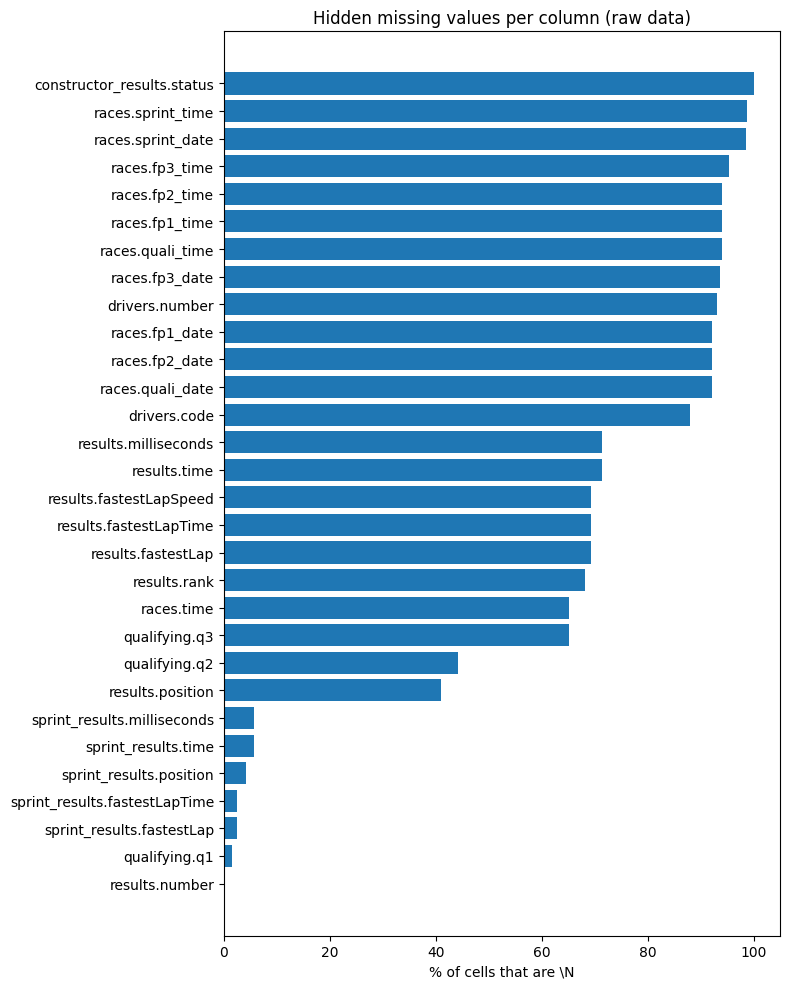

,table,column,backslash_N,percent
0,constructor_results,status,12608,99.9
1,races,sprint_time,1110,98.7
2,races,sprint_date,1107,98.4
3,races,fp3_time,1072,95.3
4,races,fp2_time,1057,94.0
5,races,fp1_time,1057,94.0
6,races,quali_time,1057,94.0
7,races,fp3_date,1053,93.6
8,drivers,number,802,93.1
9,races,fp1_date,1035,92.0


In [5]:
rows = []
for name, df in raw.items():
    for col in df.columns:
        n = int((df[col] == r"\N").sum())
        if n > 0:
            rows.append({"table": name, "column": col,
                         "backslash_N": n,
                         "percent": round(100 * n / len(df), 1)})

sentinels = (pd.DataFrame(rows)
             .sort_values("percent", ascending=False)
             .reset_index(drop=True))

labels = sentinels["table"] + "." + sentinels["column"]
plt.figure(figsize=(8, 0.3 * len(sentinels) + 1))
plt.barh(labels[::-1], sentinels["percent"][::-1])
plt.xlabel("% of cells that are \\N")
plt.title("Hidden missing values per column (raw data)")
plt.tight_layout()
plt.show()

sentinels

In [6]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"],
}

rows = []
for name, key in PRIMARY_KEYS.items():
    df = raw[name]
    missing = (df[key].isna() | (df[key] == r"\N")).any(axis=1)
    rows.append({"table": name,
                 "primary_key": ", ".join(key),
                 "missing_keys": int(missing.sum()),
                 "duplicate_keys": int(df.duplicated(subset=key).sum())})

pd.DataFrame(rows)

,table,primary_key,missing_keys,duplicate_keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


In [7]:
FOREIGN_KEYS = [
    # (child table, column, parent table, parent key)
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
]

rows = []
for child, col, parent, pk in FOREIGN_KEYS:
    orphans = ~raw[child][col].isin(raw[parent][pk])
    rows.append({"child": f"{child}.{col}",
                 "parent": f"{parent}.{pk}",
                 "orphan_rows": int(orphans.sum())})

pd.DataFrame(rows)

,child,parent,orphan_rows
0,races.circuitId,circuits.circuitId,0
1,races.year,seasons.year,0
2,results.raceId,races.raceId,0
3,results.driverId,drivers.driverId,0
4,results.constructorId,constructors.constructorId,0
5,results.statusId,status.statusId,0
6,qualifying.raceId,races.raceId,0
7,qualifying.driverId,drivers.driverId,0
8,qualifying.constructorId,constructors.constructorId,0
9,sprint_results.raceId,races.raceId,0


Result rows in total:         26759
Rows involved in duplicates:  176
Driver-race pairs affected:   85


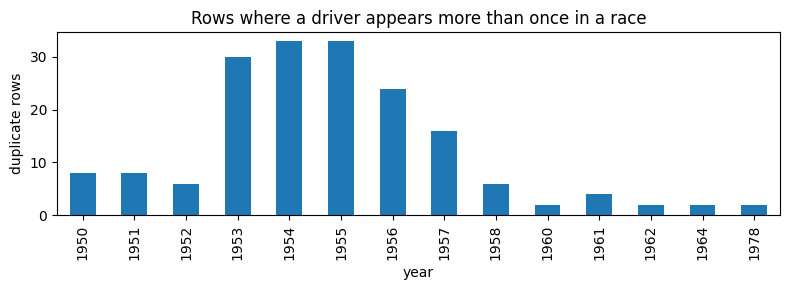

,year,name,driverId,constructorId,grid,positionText,positionOrder,points
20096,1950,Indianapolis 500,529,150,8,R,31,0.0
20178,1950,Indianapolis 500,529,113,9,5,5,1.0
20142,1950,French Grand Prix,627,154,6,R,12,0.0
20181,1950,French Grand Prix,627,154,15,6,6,0.0
20163,1950,Italian Grand Prix,579,51,1,R,15,1.0
20183,1950,Italian Grand Prix,579,51,7,R,13,0.0
20165,1950,Italian Grand Prix,647,6,2,R,17,0.0
20182,1950,Italian Grand Prix,647,6,6,2,2,3.0
19927,1951,French Grand Prix,579,51,1,11,11,0.0
20185,1951,French Grand Prix,579,51,7,1,1,5.0


In [8]:
# merge makes a new table; raw stays untouched
res = raw["results"].merge(raw["races"][["raceId", "year", "name"]], on="raceId")

dup_mask = res.duplicated(subset=["raceId", "driverId"], keep=False)
dups = res[dup_mask]

print("Result rows in total:        ", len(res))
print("Rows involved in duplicates: ", len(dups))
print("Driver-race pairs affected:  ", dups.groupby(["raceId", "driverId"]).ngroups)

dups.groupby("year").size().plot(kind="bar", figsize=(8, 3))
plt.ylabel("duplicate rows")
plt.title("Rows where a driver appears more than once in a race")
plt.tight_layout()
plt.show()

cols = ["year", "name", "driverId", "constructorId", "grid",
        "positionText", "positionOrder", "points"]
dups.sort_values(["year", "raceId", "driverId"])[cols].head(12)

### Audit findings

- **Sentinels:** `\N` appears in 30 columns (table above). Most mean "does not apply" rather than lost data:
  - `results.position` 40.9%: drivers who were not classified. The target uses `positionOrder`, which is always filled.
  - `qualifying.q2` / `q3` 44.1% / 65.0%: drivers eliminated before those sessions, and older one-session formats.
  - `results.time`, `milliseconds` and the fastest-lap columns 68-71%: post-race information that is never used as a feature.
  - `qualifying` also has 68 genuinely empty cells.
- **Primary keys:** unique and non-null in all 14 tables.
- **Foreign keys:** 23 relationships checked, 0 orphan rows, so joins will not silently drop rows.
- **Grain:** 176 result rows cover 85 (raceId, driverId) pairs, mostly in 1950-1957 (shared drives). Handled in Section 3.
- **Hidden sentinel:** `results.grid` has no `\N`, but uses 0 for "no grid slot". Examined in Section 3.

# 3. Cleaning

\N cells left in clean: 0
\N cells still in raw:  122887 (results table, unchanged)


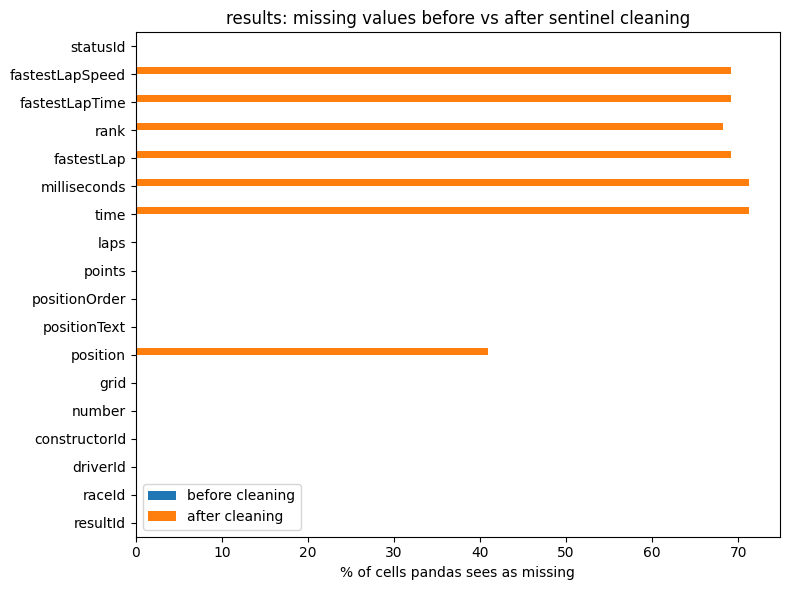

In [9]:
# replace() returns new tables, so raw is not modified
clean = {name: df.replace(r"\N", np.nan) for name, df in raw.items()}

left = sum(int((df == r"\N").sum().sum()) for df in clean.values())
print("\\N cells left in clean:", left)
print("\\N cells still in raw: ", int((raw["results"] == r"\N").sum().sum()), "(results table, unchanged)")

# Before/after: what pandas believes is missing in results
before = raw["results"].isna().mean() * 100
after = clean["results"].isna().mean() * 100
pd.DataFrame({"before cleaning": before, "after cleaning": after}).plot(
    kind="barh", figsize=(8, 6))
plt.xlabel("% of cells pandas sees as missing")
plt.title("results: missing values before vs after sentinel cleaning")
plt.tight_layout()
plt.show()

In [10]:
# 1) Numbers that were stored as text because \N was mixed in
NUMERIC = {
    "results": ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapSpeed"],
    "sprint_results": ["position", "milliseconds", "fastestLap"],
    "drivers": ["number"],
}
for table, num_cols in NUMERIC.items():
    for col in num_cols:
        clean[table][col] = pd.to_numeric(clean[table][col])

# 2) Dates
clean["races"]["date"] = pd.to_datetime(clean["races"]["date"])
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"])
for col in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    clean["races"][col] = pd.to_datetime(clean["races"][col])

# 3) Lap times: "1:26.572" -> 86.572 seconds
def lap_to_seconds(text):
    if pd.isna(text):
        return np.nan
    try:
        seconds = 0.0
        for part in str(text).split(":"):
            seconds = seconds * 60 + float(part)
        return seconds
    except ValueError:
        return np.nan   # unreadable text becomes missing; counted below

for col in ["q1", "q2", "q3"]:
    new = clean["qualifying"][col].apply(lap_to_seconds)
    unreadable = int((clean["qualifying"][col].notna() & new.isna()).sum())
    print(f"qualifying.{col}: {unreadable} unreadable values")
    clean["qualifying"][col + "_sec"] = new

clean["results"]["fastestLapTime_sec"] = clean["results"]["fastestLapTime"].apply(lap_to_seconds)

print()
print(clean["results"][["position", "milliseconds", "rank"]].dtypes)
print(clean["races"]["date"].dtype)
clean["qualifying"][["q1", "q1_sec", "q3", "q3_sec"]].dropna().head(3)

qualifying.q1: 0 unreadable values
qualifying.q2: 0 unreadable values
qualifying.q3: 0 unreadable values

position        float64
milliseconds    float64
rank            float64
dtype: object
datetime64[ns]


,q1,q1_sec,q3,q3_sec
0,1:26.572,86.572,1:26.714,86.714
1,1:26.103,86.103,1:26.869,86.869
2,1:25.664,85.664,1:27.079,87.079


### Sentinel handling and semantic typing

- **Sentinels:** `\N` is replaced by a real missing value (NaN) in the copies: 0 remain in `clean`, while `raw.results` still holds all 122,887. Before cleaning, pandas saw 0% missing values in `results`; afterwards the true gaps are visible (chart above): about 71% for race time, 68-69% for fastest-lap data and 40.9% for `position`.
- **Types:** numeric columns stored as text (`position`, `milliseconds`, `rank`, ...) are converted to numbers; race dates and dates of birth to dates; qualifying lap times such as `1:26.572` to seconds (86.572). All q1-q3 values converted (0 unreadable).

### Duplicate handling: one row per (raceId, driverId)

The audit found 176 rows covering 85 driver-race pairs where a driver appears more than once. Most are shared drives from 1950-1957, when a driver could take over a teammate's car during the race. Nine pairs come later (1958-1978): three are drivers entered in two cars who never started, and six are car changes, which no longer earned points after 1957.

**Rule:** keep the row with the best (lowest) `positionOrder`. We removed 91 rows, leaving 26,668.

**Why this rule:**
- Our target asks whether the driver finished on the podium. If any of his cars finished in the top 3, he was classified there.
- `positionOrder` is never missing, so the rule always gives one answer.
- The alternative "keep the car he started in" cannot be applied: both rows usually have a non-zero grid.

**Limitations:**
- The kept row's `grid` and `constructorId` may belong to the car the driver took over (example: 1960 Argentine GP, driver 475 started on pole but the kept row has grid 8).
- 18 races have 4 or 5 podium rows, because two drivers shared a podium car and both are classified. This adds 20 podium rows.
- At most 85 of 26,668 rows (0.3%) are affected, all before 1979.

In [11]:
# Duplicates after 1957 (double entries and car changes)
late = dups[dups["year"] > 1957].sort_values(["year", "raceId", "driverId"])
display(late[cols])

# Rule: keep the row with the best (lowest) positionOrder
rows_before = len(clean["results"])
clean["results"] = (
    clean["results"]
    .sort_values(["raceId", "driverId", "positionOrder", "resultId"])
    .drop_duplicates(subset=["raceId", "driverId"], keep="first")
    .reset_index(drop=True)
)

print("Rows before:", rows_before)
print("Rows after: ", len(clean["results"]))
print("Removed:    ", rows_before - len(clean["results"]), "(expected 91)")
assert not clean["results"].duplicated(["raceId", "driverId"]).any()
print("Grain check passed: (raceId, driverId) is unique")

,year,name,driverId,constructorId,grid,positionText,positionOrder,points
18509,1958,Monaco Grand Prix,541,87,0,F,17,0.0
18519,1958,Monaco Grand Prix,541,66,0,F,27,0.0
18611,1958,French Grand Prix,479,118,5,R,18,0.0
20293,1958,French Grand Prix,479,118,10,R,14,0.0
18693,1958,Italian Grand Prix,566,105,17,R,18,0.0
20294,1958,Italian Grand Prix,566,105,11,4,4,0.0
18082,1960,Argentine Grand Prix,475,170,1,R,17,0.0
20295,1960,Argentine Grand Prix,475,170,8,3,3,0.0
17961,1961,British Grand Prix,475,102,20,D,19,0.0
17963,1961,British Grand Prix,475,172,5,R,21,0.0


Rows before: 26759
Rows after:  26668
Removed:     91 (expected 91)
Grain check passed: (raceId, driverId) is unique


In [12]:
r = clean["results"]

# Check A: how many podium rows does each race have?
podiums_per_race = r[r["positionOrder"] <= 3].groupby("raceId").size()
print("Podium rows per race -> number of races")
print(podiums_per_race.value_counts().sort_index())

# Check B: what does grid == 0 really mean?
g0 = r[r["grid"] == 0]
print("\nRows with grid == 0:", len(g0), f"({100 * len(g0) / len(r):.1f}%)")
print("\nTheir positionText codes:")
print(g0["positionText"].value_counts().head(10))
print("\nPodiums from grid 0:", int((g0["positionOrder"] <= 3).sum()))

Podium rows per race -> number of races
3    1107
4      16
5       2
Name: count, dtype: int64

Rows with grid == 0: 1635 (6.1%)

Their positionText codes:
positionText
F     1346
W      202
R       14
17       9
13       7
E        7
10       7
D        6
18       6
16       6
Name: count, dtype: int64

Podiums from grid 0: 0


### Checks on the cleaned results

- **Podium rows per race:** 1,107 races have exactly 3, 16 have 4 and 2 have 5, because two drivers who shared a podium car are both classified. Total: 3,395 podium rows.
- **What `grid = 0` means:** 1,635 rows (6.1%). 1,346 are F (failed to qualify) and 202 are W (withdrawn); most of the rest raced (pit-lane starts). No driver with grid 0 has ever finished on the podium.
- **Consequence:** grid 0 cannot stay the number 0, because a model would read it as better than pole. In Section 6 it is encoded as one slot behind the last car, plus a separate flag (`grid_is_zero`).

# 4. EDA after cleaning

In [13]:
base = clean["results"].merge(
    clean["races"][["raceId", "year", "round", "date", "circuitId", "name"]],
    on="raceId", how="left")

assert len(base) == len(clean["results"])   # the join must not add or lose rows

base["podium"] = (base["positionOrder"] <= 3).astype(int)

print("Rows:", len(base))
print("Podium rows:", base["podium"].sum())
print(f"Overall podium rate: {100 * base['podium'].mean():.1f}%")

Rows: 26668
Podium rows: 3395
Overall podium rate: 12.7%


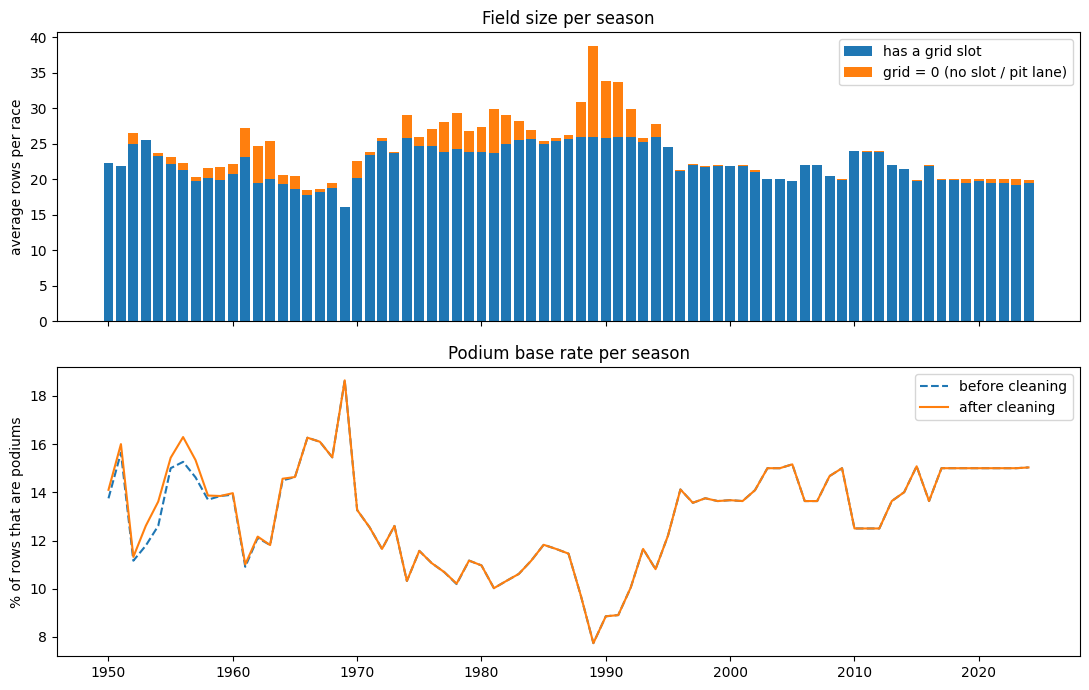

,races,with_grid_per_race,no_grid_per_race,podium_rate
year,,,,
1950,7,22.286,0.000,0.141
1955,7,22.143,1.000,0.154
1970,13,20.231,2.385,0.133
1989,16,26.000,12.750,0.077
2000,17,21.824,0.118,0.137
2010,19,24.000,0.000,0.125
2019,21,19.429,0.571,0.150
2024,24,19.500,0.458,0.150


In [14]:
season = base.groupby("year").agg(
    races=("raceId", "nunique"),
    rows=("resultId", "size"),
    no_grid=("grid", lambda g: (g == 0).sum()),
    podium_rate=("podium", "mean"),
)
season["with_grid_per_race"] = (season["rows"] - season["no_grid"]) / season["races"]
season["no_grid_per_race"] = season["no_grid"] / season["races"]

# Same podium rate on the raw data, to show the effect of cleaning
raw_base = raw["results"].merge(raw["races"][["raceId", "year"]], on="raceId")
raw_rate = (raw_base["positionOrder"] <= 3).groupby(raw_base["year"]).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].bar(season.index, season["with_grid_per_race"], label="has a grid slot")
axes[0].bar(season.index, season["no_grid_per_race"],
            bottom=season["with_grid_per_race"], label="grid = 0 (no slot / pit lane)")
axes[0].set_ylabel("average rows per race")
axes[0].set_title("Field size per season")
axes[0].legend()

axes[1].plot(raw_rate.index, raw_rate * 100, "--", label="before cleaning")
axes[1].plot(season.index, season["podium_rate"] * 100, label="after cleaning")
axes[1].set_ylabel("% of rows that are podiums")
axes[1].set_title("Podium base rate per season")
axes[1].legend()

plt.tight_layout()
plt.show()

season.loc[[1950, 1955, 1970, 1989, 2000, 2010, 2019, 2024],
           ["races", "with_grid_per_race", "no_grid_per_race", "podium_rate"]].round(3)

Duplicate (raceId, driverId) in qualifying: 0


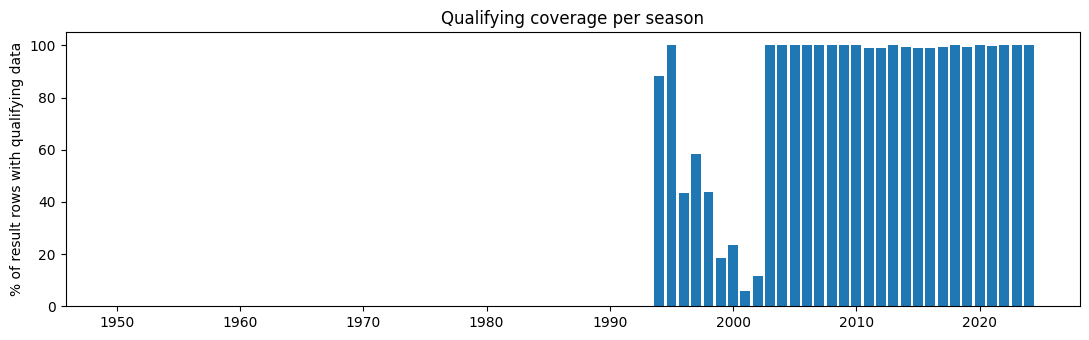

First season with any qualifying data: 1994
Seasons with coverage above 0% but below 90%: [1994, 1996, 1997, 1998, 1999, 2000, 2001, 2002]
Rows with qualifying data overall: 39.4%


In [15]:
q_keys = set(zip(clean["qualifying"]["raceId"], clean["qualifying"]["driverId"]))
base["has_quali"] = [key in q_keys for key in zip(base["raceId"], base["driverId"])]

print("Duplicate (raceId, driverId) in qualifying:",
      int(clean["qualifying"].duplicated(["raceId", "driverId"]).sum()))

coverage = base.groupby("year")["has_quali"].mean() * 100

plt.figure(figsize=(11, 3.5))
plt.bar(coverage.index, coverage.values)
plt.ylabel("% of result rows with qualifying data")
plt.title("Qualifying coverage per season")
plt.tight_layout()
plt.show()

print("First season with any qualifying data:", coverage[coverage > 0].index.min())
print("Seasons with coverage above 0% but below 90%:",
      list(coverage[(coverage > 0) & (coverage < 90)].index))
print(f"Rows with qualifying data overall: {100 * base['has_quali'].mean():.1f}%")

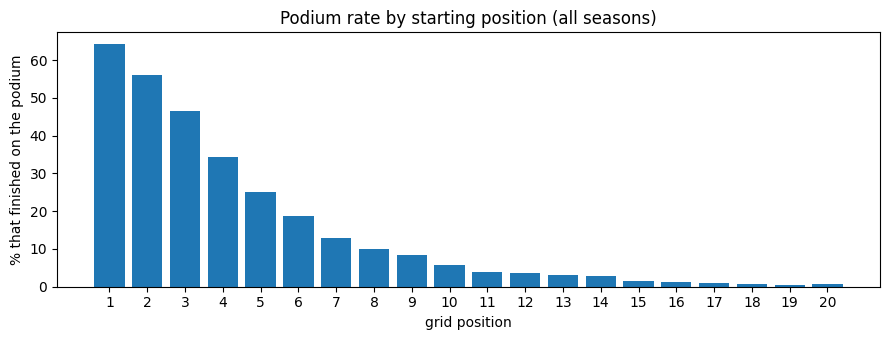

,podium_%,rows
grid,,
1,64.1,1124
2,55.9,1119
3,46.4,1127
4,34.2,1128
5,25.1,1121
6,18.7,1120


In [16]:
started = base[(base["grid"] >= 1) & (base["grid"] <= 20)]
by_grid = started.groupby("grid")["podium"].agg(["mean", "size"])

plt.figure(figsize=(9, 3.5))
plt.bar(by_grid.index, by_grid["mean"] * 100)
plt.xticks(range(1, 21))
plt.xlabel("grid position")
plt.ylabel("% that finished on the podium")
plt.title("Podium rate by starting position (all seasons)")
plt.tight_layout()
plt.show()

(by_grid.head(6) * [100, 1]).round(1).rename(columns={"mean": "podium_%", "size": "rows"})

### EDA findings and the decisions they support

- **Target and imbalance:** 3,395 of 26,668 rows (12.7%) are podiums. A model that always predicts "no podium" would be 87% accurate, so we evaluate with PR-AUC, ROC-AUC and F1 instead of accuracy.
- **Field size (first chart):** the number of starters per race is stable (about 16-26). Rows without a grid slot are concentrated in the early 1960s, the mid-1970s to early 1980s, and above all 1988-1992 (1989: about 39 entries per race for 26 starters). These drivers never started, so they are removed from the modeling population (Section 7).
- **Podium base rate (second chart, table):** roughly 3 divided by the number of entries per race: 7.7% in 1989, 12.5% in 2010 (24 cars), 15.0% in 2019 and 2024 (20 cars). Removing duplicates raised the 1950s rates slightly and changed nothing afterwards.
- **Qualifying coverage:** no qualifying data before 1994, patchy 1994-2002, essentially complete from 2003; 39.4% of rows overall. Qualifying features are therefore missing for most old seasons (flag `has_quali`), and the qualifying comparison in Question 1 is limited to 2003 onwards.
- **Grid position:** podium rate from pole 64.1%, then 55.9%, 46.4%, 34.2%, 25.1%, 18.7% for grid 2-6 (about 1,120 rows each), falling to almost zero by 15th. Grid is the strongest candidate feature. This is an association: fast cars both qualify and finish well.

# 5. Data-engineering questions
## Question 1: front-row conversion by circuit, before and after 2014

In [17]:
circ = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
q1 = base.merge(circ, on="circuitId", how="left")
assert len(q1) == len(base)

front = q1[q1["grid"].isin([1, 2])]
print("Front-row starts:", len(front), "in", front["raceId"].nunique(), "races")
print(f"Conversion 1950-2013: {100 * front[front['year'] < 2014]['podium'].mean():.1f}%")
print(f"Conversion 2014-2024: {100 * front[front['year'] >= 2014]['podium'].mean():.1f}%")

MIN_STARTS = 10

def conversion(df):
    out = df.groupby("circuit")["podium"].agg(rate="mean", starts="size")
    out["rate"] = (out["rate"] * 100).round(1)
    return out[out["starts"] >= MIN_STARTS].sort_values("rate", ascending=False)

old = conversion(front[front["year"] < 2014])
new = conversion(front[front["year"] >= 2014])

print("\nCircuits ranked: before 2014 =", len(old), "| 2014 onward =", len(new))
print("\nTop 10 before 2014");  display(old.head(10))
print("Top 10 from 2014");      display(new.head(10))
print("Bottom 5 from 2014");    display(new.tail(5))

Front-row starts: 2243 in 1124 races
Conversion 1950-2013: 56.0%
Conversion 2014-2024: 76.0%

Circuits ranked: before 2014 = 44 | 2014 onward = 19

Top 10 before 2014


,rate,starts
circuit,,
Circuit de Nevers Magny-Cours,80.6,36
Istanbul Park,78.6,14
Dijon-Prenois,75.0,12
Circuit Bremgarten,70.0,10
Suzuka Circuit,70.0,50
Sepang International Circuit,70.0,30
Hungaroring,67.9,56
Bahrain International Circuit,66.7,18
Autódromo do Estoril,65.4,26


Top 10 from 2014


,rate,starts
circuit,,
Suzuka Circuit,88.9,18
Yas Marina Circuit,86.4,22
Circuit de Monaco,85.0,20
Circuit de Spa-Francorchamps,81.8,22
Circuit de Barcelona-Catalunya,81.8,22
Sochi Autodrom,81.2,16
Circuit of the Americas,80.0,20
Autódromo José Carlos Pace,78.9,19
Shanghai International Circuit,78.6,14


Bottom 5 from 2014


,rate,starts
circuit,,
Albert Park Grand Prix Circuit,72.2,18
Bahrain International Circuit,66.7,24
Baku City Circuit,62.5,16
Autódromo Hermanos Rodríguez,61.1,18
Hungaroring,59.1,22


Circuits with enough races in both eras: 16
Spearman rank correlation between eras: -0.03


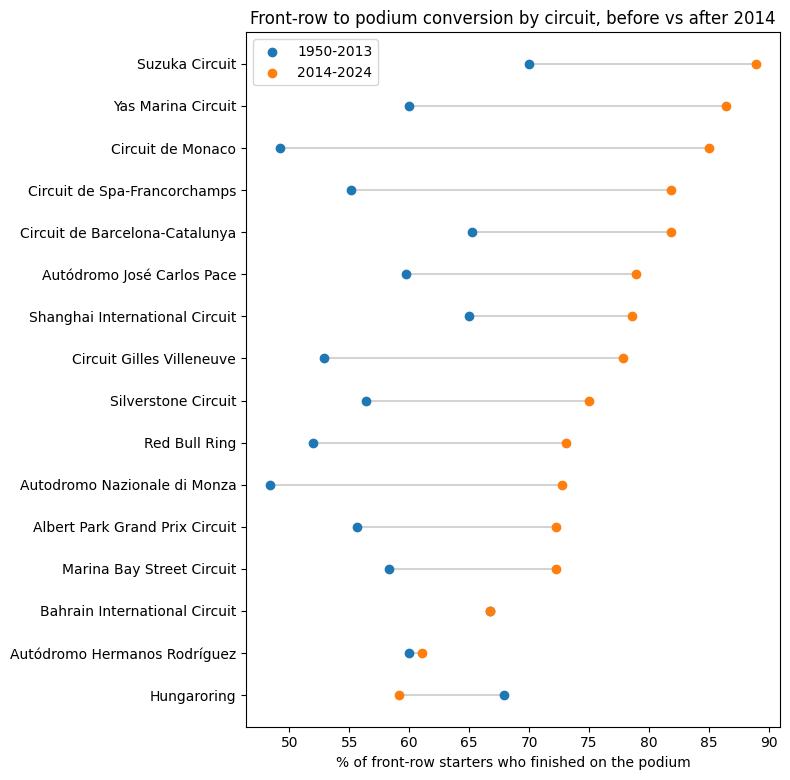

,rate_old,rank_old,rate_new,rank_new,starts_old,starts_new
circuit,,,,,,
Suzuka Circuit,70.0,1,88.9,1,50,18
Yas Marina Circuit,60.0,6,86.4,2,10,22
Circuit de Monaco,49.2,15,85.0,3,120,20
Circuit de Barcelona-Catalunya,65.2,4,81.8,4,46,22
Circuit de Spa-Francorchamps,55.1,12,81.8,4,89,22
Autódromo José Carlos Pace,59.7,8,78.9,6,62,19
Shanghai International Circuit,65.0,5,78.6,7,20,14
Circuit Gilles Villeneuve,52.9,13,77.8,8,68,18
Silverstone Circuit,56.4,10,75.0,9,94,24


In [18]:
both = old.join(new, lsuffix="_old", rsuffix="_new", how="inner")
both["rank_old"] = both["rate_old"].rank(ascending=False, method="min").astype(int)
both["rank_new"] = both["rate_new"].rank(ascending=False, method="min").astype(int)
both = both.sort_values("rate_new")

spearman = both["rate_old"].corr(both["rate_new"], method="spearman")
print("Circuits with enough races in both eras:", len(both))
print(f"Spearman rank correlation between eras: {spearman:.2f}")

plt.figure(figsize=(8, 0.4 * len(both) + 1.5))
plt.hlines(both.index, both["rate_old"], both["rate_new"], color="lightgray")
plt.scatter(both["rate_old"], both.index, label="1950-2013", zorder=3)
plt.scatter(both["rate_new"], both.index, label="2014-2024", zorder=3)
plt.xlabel("% of front-row starters who finished on the podium")
plt.title("Front-row to podium conversion by circuit, before vs after 2014")
plt.legend()
plt.tight_layout()
plt.show()

both.sort_values("rank_new")[["rate_old", "rank_old", "rate_new", "rank_new", "starts_old", "starts_new"]]

In [19]:
qpos = clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
qg = q1.merge(qpos, on=["raceId", "driverId"], how="inner")
qg = qg[qg["year"] >= 2003]          # seasons with complete qualifying coverage (Cell 15)

quali_front = qg[qg["quali_pos"].isin([1, 2])]
grid_front = qg[qg["grid"].isin([1, 2])]
lost = quali_front[~quali_front["grid"].isin([1, 2])]

print("2003-2024 only")
print("Qualified on the front row:      ", len(quali_front))
print("...but did not start there:      ", len(lost), f"({100 * len(lost) / len(quali_front):.1f}%)")
print(f"Podium rate, qualified front row: {100 * quali_front['podium'].mean():.1f}%")
print(f"Podium rate, started front row:   {100 * grid_front['podium'].mean():.1f}%")
print(f"Podium rate, lost the front row:  {100 * lost['podium'].mean():.1f}%")

display(lost.sort_values("year", ascending=False)
            [["year", "name", "driverId", "quali_pos", "grid", "positionOrder"]].head(8))

2003-2024 only
Qualified on the front row:       856
...but did not start there:       38 (4.4%)
Podium rate, qualified front row: 70.7%
Podium rate, started front row:   72.2%
Podium rate, lost the front row:  28.9%


,year,name,driverId,quali_pos,grid,positionOrder
10281,2024,Belgian Grand Prix,830,1,11,4
10152,2024,Emilia Romagna Grand Prix,857,2,5,4
9983,2023,Las Vegas Grand Prix,832,2,12,6
9967,2023,São Paulo Grand Prix,844,2,0,20
9717,2023,Canadian Grand Prix,807,2,5,15
9606,2023,Saudi Arabian Grand Prix,844,2,12,7
9802,2023,Belgian Grand Prix,830,1,6,1
9507,2022,United States Grand Prix,844,2,12,3


### Answer to Question 1

**Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?**

- **Tables joined:** results, races, circuits, and qualifying for the last part.
- **Grain:** one row per front-row starter per race (2,243 starts in 1,124 races).
- **Definition:** front row = `grid` 1 or 2. A circuit is ranked only with at least 10 front-row starts in the era.

**Result.** Before 2014, Magny-Cours converted most often (80.6%); Suzuka (70.0%) and Hungaroring (67.9%) are the best-supported circuits near the top. From 2014, Suzuka leads (88.9%), followed by Yas Marina (86.4%) and Monaco (85.0%); Hungaroring is last (59.1%).

**Does the ranking change?** Yes. Overall conversion rose from 56.0% to 76.0%, so we compare ranks, not raw rates. Among the 16 circuits with enough races in both eras, the Spearman rank correlation is -0.03, meaning the two rankings are unrelated. Monaco rose from 15th to 3rd, Hungaroring fell from 2nd to 16th, and Bahrain stayed at 66.7% but dropped from 3rd to 14th. Only Suzuka is stable (1st in both).

**Qualifying position vs grid.** In 2003-2024, 38 of 856 front-row qualifiers (4.4%) did not start there, usually because of penalties. Their podium rate was 28.9%, against 72.2% for drivers who started on the front row. The two columns are different, so we used `grid`.

**Missingness.** `grid` is complete for all seasons. Qualifying data starts in 1994 and is complete only from 2003, so the comparison is limited to 2003-2024.

**Pre-race cutoff.** Grid is known before the race; the podium is the outcome we measure. This is a descriptive analysis. If a circuit conversion rate were used as a model feature, it would have to be computed from earlier races only.

**Limitation.** Hybrid-era circuits have only 14 to 26 front-row starts each, so one podium changes a rate by about 5 points. Part of the reshuffling may be chance.


## Question 2: home-race effect, controlled for starting position

In [20]:
NAT_TO_COUNTRY = {
    "British": "UK", "American": "USA", "Italian": "Italy", "French": "France",
    "German": "Germany", "East German": "Germany", "Brazilian": "Brazil",
    "Argentine": "Argentina", "Spanish": "Spain", "Belgian": "Belgium",
    "Dutch": "Netherlands", "Austrian": "Austria", "Australian": "Australia",
    "Canadian": "Canada", "Japanese": "Japan", "Mexican": "Mexico",
    "Monegasque": "Monaco", "Swiss": "Switzerland", "Swedish": "Sweden",
    "South African": "South Africa", "Portuguese": "Portugal",
    "Hungarian": "Hungary", "Chinese": "China", "Russian": "Russia",
    "Indian": "India", "Malaysian": "Malaysia",    "Argentinian": "Argentina",
}

q2 = q1.merge(clean["drivers"][["driverId", "nationality"]], on="driverId", how="left")
assert len(q2) == len(q1)
q2["nationality"] = q2["nationality"].str.strip()

q2["country"] = q2["country"].replace({"United States": "USA"})   # one spelling only
q2["home_country"] = q2["nationality"].map(NAT_TO_COUNTRY)
q2["home"] = q2["home_country"] == q2["country"]

print("Circuit countries in the data:")
print(sorted(q2["country"].unique()))

print("\nNationalities with no mapping (rows):")
print(q2[q2["home_country"].isna()]["nationality"].value_counts())

print("\nHome rows:", int(q2["home"].sum()), f"({100 * q2['home'].mean():.1f}% of all rows)")
print("\nHome rows by nationality (top 8):")
print(q2[q2["home"]]["nationality"].value_counts().head(8))

indy = q2[q2["name"] == "Indianapolis 500"]
print("\nIndianapolis 500: races =", indy["raceId"].nunique(),
      "| rows =", len(indy), f"| home rows = {100 * indy['home'].mean():.1f}%")

Circuit countries in the data:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']

Nationalities with no mapping (rows):
nationality
Finnish              1193
New Zealander         407
Danish                221
Colombian             125
Thai                  124
Venezuelan            120
Polish                 99
Irish                  92
Chilean                37
Rhodesian              18
Liechtensteiner        13
Indonesian             12
Uruguayan               7
Czech                   3
American-Italian        2
Argentine-Italian       2
Name: count, dtype: int64

Home rows: 2490 (9.3% of all rows)

Home rows by nationality (top 8):
nationality
American     500
British

--- All races ---
Raw podium rate, home: 11.5%   away: 13.8%
Home rows: 2322 | expected podiums: 271.2 | actual: 266
Actual / expected: 0.98

--- Without Indianapolis 500 ---
Raw podium rate, home: 11.8%   away: 13.8%
Home rows: 1942 | expected podiums: 234.7 | actual: 230
Actual / expected: 0.98



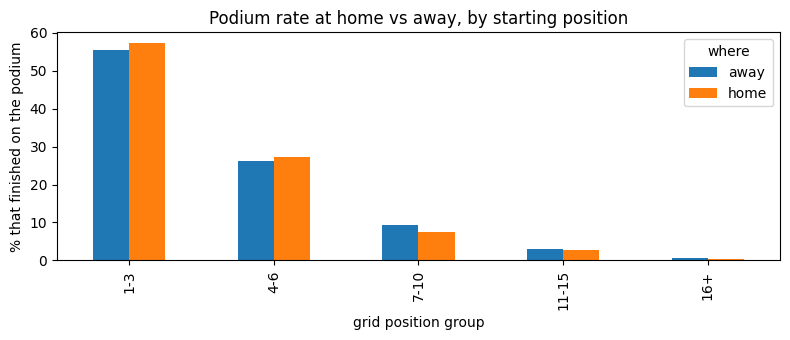

where,away_podium_%,home_podium_%,away_rows,home_rows
grid_group,,,,
1-3,55.5,57.2,3106,229
4-6,26.1,27.1,3108,225
7-10,9.3,7.4,4124,337
11-15,3.0,2.7,5136,414
16+,0.7,0.3,7236,737


In [21]:
def home_effect(df, label):
    d = df[df["grid"] >= 1]                       # real grid slots only
    away_rate = d[~d["home"]].groupby("grid")["podium"].mean()
    home = d[d["home"]]
    expected = home["grid"].map(away_rate).fillna(0).sum()
    actual = home["podium"].sum()
    print(f"--- {label} ---")
    print(f"Raw podium rate, home: {100 * home['podium'].mean():.1f}%   "
          f"away: {100 * d[~d['home']]['podium'].mean():.1f}%")
    print(f"Home rows: {len(home)} | expected podiums: {expected:.1f} | actual: {actual}")
    print(f"Actual / expected: {actual / expected:.2f}\n")

no_indy = q2[q2["name"] != "Indianapolis 500"]
home_effect(q2, "All races")
home_effect(no_indy, "Without Indianapolis 500")

# Picture: same comparison in grid groups (without Indianapolis 500)
d = no_indy[no_indy["grid"] >= 1].copy()
d["grid_group"] = pd.cut(d["grid"], bins=[0, 3, 6, 10, 15, 40],
                         labels=["1-3", "4-6", "7-10", "11-15", "16+"])
d["where"] = np.where(d["home"], "home", "away")
table = d.groupby(["grid_group", "where"], observed=True)["podium"].agg(["mean", "size"]).unstack()

(table["mean"] * 100).plot(kind="bar", figsize=(8, 3.5))
plt.xlabel("grid position group")
plt.ylabel("% that finished on the podium")
plt.title("Podium rate at home vs away, by starting position")
plt.tight_layout()
plt.show()

(table["mean"] * 100).round(1).join(table["size"], lsuffix="_podium_%", rsuffix="_rows")

### Answer to Question 2

**Do drivers podium more often at a circuit in their home country, after controlling for starting position?**

- **Tables joined:** results, races, circuits (country), drivers (nationality).
- **Grain:** one row per driver per race. Rows with `grid` 0 are excluded because they have no starting position to control for.
- **Definition:** a home race is one where the driver's nationality maps to the circuit's country (2,490 rows, 9.3%).

**Result.** The raw podium rate is lower at home (11.5%) than away (13.8%). This is misleading: many home entries are local drivers at the back of the grid (737 home rows start 16th or lower).

**Control.** For each grid position we computed the away podium rate, then used it to calculate how many podiums home drivers would be expected to score. Home drivers scored 266 against 271.2 expected, a ratio of 0.98. Within grid groups, home and away rates differ by at most 2 points (for grid 1-3: 57.2% home, 55.5% away).

**Conclusion.** There is no evidence of a home advantage once starting position is taken into account.

**Indianapolis 500.** These 11 races (1950-1960) have 381 rows, 99.7% of them home drivers, and account for most American home rows. Without them the ratio is still 0.98 (230 actual, 234.7 expected). We report the version without them as the main result.

**Missingness and limitations.** Nationality is not the same as where a driver lives or grew up. Drivers from countries without a race (for example Finland) are always "away". Four rows with mixed nationalities are unmapped.

**Pre-race cutoff.** Nationality, circuit country and grid are all known before the race, so a home-race flag would be a valid feature. This result suggests it would add little.

## Question 3: mechanical-retirement rate by constructor, 2014-2021 vs 2022-2024

In [22]:
cons = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})
q3 = (base.merge(clean["status"], on="statusId", how="left")
          .merge(cons, on="constructorId", how="left"))
assert len(q3) == len(base)

q3 = q3[q3["year"] >= 2014].copy()
print("Rows in 2014-2024:", len(q3))
print("Different statuses:", q3["status"].nunique())
print()
print(q3["status"].value_counts().to_string())

Rows in 2014-2024: 4626
Different statuses: 66

status
Finished            2403
+1 Lap              1178
+2 Laps              208
Collision            150
Accident              85
Engine                81
Collision damage      59
Retired               50
Brakes                49
Gearbox               42
Power Unit            42
Suspension            25
+3 Laps               24
Hydraulics            15
Withdrew              14
Electrical            14
Power loss            13
Wheel                 11
Spun off              11
Disqualified          11
Oil leak              10
Overheating            8
Mechanical             7
Puncture               7
Water pressure         7
Turbo                  6
+4 Laps                6
ERS                    5
Fuel pressure          5
Battery                5
Exhaust                5
Tyre                   4
Electronics            4
Water leak             4
Undertray              4
Front wing             3
Radiator               3
Wheel nut           

In [23]:
MECHANICAL = {
    "Engine", "Power Unit", "Gearbox", "Brakes", "Suspension", "Hydraulics",
    "Electrical", "Power loss", "Wheel", "Oil leak", "Overheating", "Mechanical",
    "Water pressure", "Turbo", "ERS", "Fuel pressure", "Battery", "Exhaust",
    "Electronics", "Water leak", "Radiator", "Wheel nut", "Transmission",
    "Steering", "Fuel leak", "Technical", "Clutch", "Oil pressure", "Vibrations",
    "Throttle", "Driveshaft", "Fuel system", "Drivetrain", "Brake duct", "Seat",
    "Spark plugs", "Water pump", "Cooling system", "Fuel pump", "Differential",
}
BORDERLINE = {"Retired", "Puncture", "Tyre", "Front wing", "Rear wing", "Undertray"}

def classify(status):
    if status == "Finished" or status.startswith("+"):
        return "finished"
    if status in MECHANICAL:
        return "mechanical"
    if status in BORDERLINE:
        return "borderline"
    return "other"

q3["outcome"] = q3["status"].apply(classify)
print("Statuses classed as 'other':", sorted(q3[q3["outcome"] == "other"]["status"].unique()))

not_started = (q3["status"] == "Withdrew") | ((q3["grid"] == 0) & (q3["laps"] == 0))
print("\nRows removed as non-starters:", int(not_started.sum()))
print(q3[not_started]["status"].value_counts().to_string())

starts = q3[~not_started].copy()
starts["era"] = np.where(starts["year"] <= 2021, "2014-2021", "2022-2024")

print("\nRace starts by era and outcome:")
print(pd.crosstab(starts["era"], starts["outcome"], margins=True))

print("\n'Retired' (no reason given) by year:")
print(starts[starts["status"] == "Retired"].groupby("year").size().to_string())

Statuses classed as 'other': ['Accident', 'Collision', 'Collision damage', 'Damage', 'Debris', 'Disqualified', 'Excluded', 'Illness', 'Out of fuel', 'Spun off', 'Withdrew']

Rows removed as non-starters: 18
status
Withdrew       14
Fuel system     1
Battery         1
Brakes          1
Engine          1

Race starts by era and outcome:
outcome    borderline  finished  mechanical  other   All
era                                                     
2014-2021          53      2660         312    230  3255
2022-2024          18      1165          76     94  1353
All                71      3825         388    324  4608

'Retired' (no reason given) by year:
year
2014     8
2015    12
2016    10
2018     2
2019     2
2020     1
2021     3
2023     3
2024     9


2014-2021: overall mechanical rate 9.6% (upper 11.2%) over 3255 starts
2022-2024: overall mechanical rate 5.6% (upper 6.9%) over 1353 starts


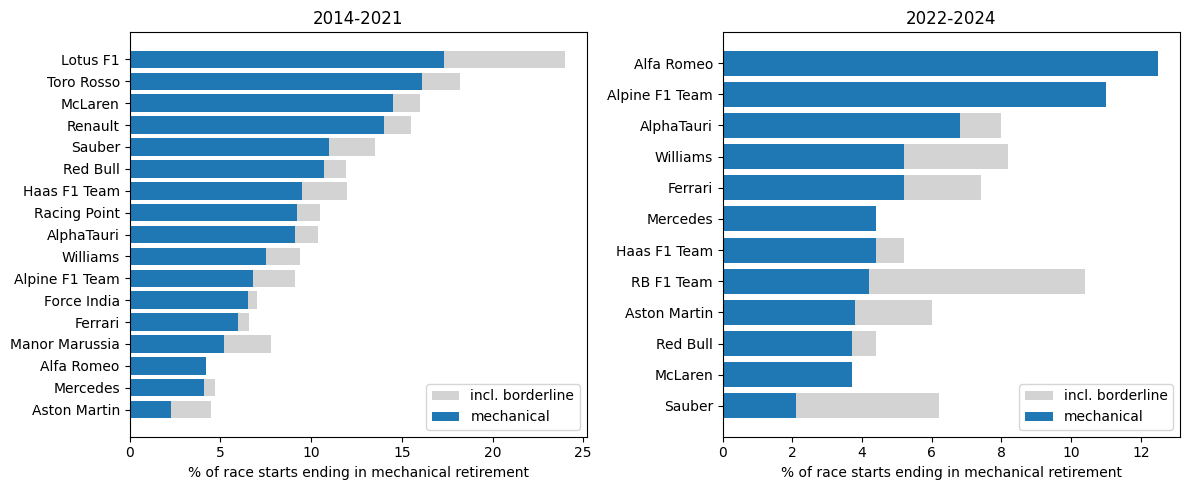

2014-2021


,constructor,starts,mechanical,rate,rate_upper
0,Lotus F1,75,13,17.3,24.0
1,Toro Rosso,242,39,16.1,18.2
2,McLaren,318,46,14.5,16.0
3,Renault,200,28,14.0,15.5
4,Sauber,200,22,11.0,13.5
5,Red Bull,319,34,10.7,11.9
6,Haas F1 Team,241,23,9.5,12.0
7,Racing Point,76,7,9.2,10.5
8,AlphaTauri,77,7,9.1,10.4
9,Williams,319,24,7.5,9.4


2022-2024


,constructor,starts,mechanical,rate,rate_upper
0,Alfa Romeo,88,11,12.5,12.5
1,Alpine F1 Team,136,15,11.0,11.0
2,AlphaTauri,88,6,6.8,8.0
3,Ferrari,135,7,5.2,7.4
4,Williams,134,7,5.2,8.2
5,Mercedes,136,6,4.4,4.4
6,Haas F1 Team,135,6,4.4,5.2
7,RB F1 Team,48,2,4.2,10.4
8,Aston Martin,133,5,3.8,6.0
9,McLaren,136,5,3.7,3.7


In [24]:
MIN_STARTS = 40     # about one full season with two cars

starts["mech"] = starts["outcome"] == "mechanical"
starts["mech_or_border"] = starts["outcome"].isin(["mechanical", "borderline"])

for era in ["2014-2021", "2022-2024"]:
    e = starts[starts["era"] == era]
    print(f"{era}: overall mechanical rate {100 * e['mech'].mean():.1f}% "
          f"(upper {100 * e['mech_or_border'].mean():.1f}%) over {len(e)} starts")

rates = starts.groupby(["era", "constructor"]).agg(
    starts=("resultId", "size"),
    mechanical=("mech", "sum"),
    rate=("mech", "mean"),
    rate_upper=("mech_or_border", "mean"),
).reset_index()
rates[["rate", "rate_upper"]] = (rates[["rate", "rate_upper"]] * 100).round(1)
rates = rates[rates["starts"] >= MIN_STARTS]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, era in zip(axes, ["2014-2021", "2022-2024"]):
    r = rates[rates["era"] == era].sort_values("rate")
    ax.barh(r["constructor"], r["rate_upper"], color="lightgray", label="incl. borderline")
    ax.barh(r["constructor"], r["rate"], label="mechanical")
    ax.set_title(era)
    ax.set_xlabel("% of race starts ending in mechanical retirement")
    ax.legend()
plt.tight_layout()
plt.show()

for era in ["2014-2021", "2022-2024"]:
    print(era)
    display(rates[rates["era"] == era].sort_values("rate", ascending=False)
            .drop(columns="era").reset_index(drop=True))

### Answer to Question 3

**Which constructors have the highest mechanical-retirement rate in 2014-2021 vs 2022-2024?**

- **Tables joined:** results, races, status, constructors.
- **Grain:** one row per race start, 2014-2024 (4,608 rows after removing 18 non-starters: status "Withdrew", or grid 0 with 0 laps).
- **Status grouping (66 values):** finished (9), mechanical (40 component failures such as Engine, Power Unit, Gearbox, Brakes, Hydraulics), other (11: crashes, driver causes, disqualifications), borderline (6: "Retired", Puncture, Tyre, Front wing, Rear wing, Undertray).
- **Minimum sample:** 40 starts in the era.

**Result.** The overall rate fell from 9.6% (312 of 3,255 starts) to 5.6% (76 of 1,353).

| Era | Highest mechanical-retirement rates |
|---|---|
| 2014-2021 | Lotus F1 17.3%, Toro Rosso 16.1%, McLaren 14.5%, Renault 14.0% |
| 2022-2024 | Alfa Romeo 12.5%, Alpine 11.0% (about twice the era average) |

McLaren improved from 14.5% to 3.7%; Alfa Romeo went from 4.2% to 12.5%; Mercedes stayed low (4.1% and 4.4%).

**Sensitivity.** Counting borderline cases as mechanical gives an upper rate. The leaders in both eras are unchanged.

**Limitations.**
- Constructors are identified by `constructorId`, so renamed teams (Toro Rosso, AlphaTauri, RB) are separate entries.
- "Retired" gives no cause and is used unevenly (30 cases in 2014-2016, 9 in 2024). Rates for the 2024-only entries RB and Sauber are uncertain: RB is 4.2% on named failures but up to 10.4% with borderline cases.
- Most 2022-2024 teams have fewer than 10 failures, so small rank differences are not meaningful.

**Pre-race cutoff.** `status` is known only after the race. It is used here for description and will never be a model feature.

# 6. Modeling table and features

In [25]:
m = base[["resultId", "raceId", "driverId", "constructorId", "year", "round", "date",
          "circuitId", "name", "grid",
          "positionText", "positionOrder", "points", "statusId",   # post-race
          "podium"]].copy()

# Time order: season, then race number within the season
m = m.sort_values(["year", "round", "positionOrder"]).reset_index(drop=True)
assert not m.duplicated(["raceId", "driverId"]).any()

POST_RACE = ["positionText", "positionOrder", "points", "statusId"]   # never features
TARGET = "podium"

# Flags for the row decisions we make at the split step
m["non_starter"] = m["positionText"].isin(["F", "W"])     # failed to qualify / withdrawn
m["is_indy500"] = m["name"] == "Indianapolis 500"
m["period"] = pd.cut(m["year"], bins=[1949, 2019, 2021, 2024],
                     labels=["train (<=2019)", "validation (2020-21)", "test (2022+)"])

print("Non-starters vs grid == 0:")
print(pd.crosstab(m["non_starter"], m["grid"] == 0))

rows = []
for period, d in m.groupby("period", observed=True):
    kept = d[~d["non_starter"] & ~d["is_indy500"]]
    rows.append({"period": period,
                 "rows": len(d),
                 "non_starters": int(d["non_starter"].sum()),
                 "indy500_rows": int(d["is_indy500"].sum()),
                 "podium_%_all_rows": round(100 * d["podium"].mean(), 1),
                 "podium_%_if_removed": round(100 * kept["podium"].mean(), 1)})
pd.DataFrame(rows)

Non-starters vs grid == 0:
grid         False  True 
non_starter              
False        24880     87
True           153   1548


,period,rows,non_starters,indy500_rows,podium_%_all_rows,podium_%_if_removed
0,train (<=2019),24529,1689,381,12.5,13.5
1,validation (2020-21),780,5,0,15.0,15.1
2,test (2022+),1359,7,0,15.0,15.1


Races without any grid information: 0


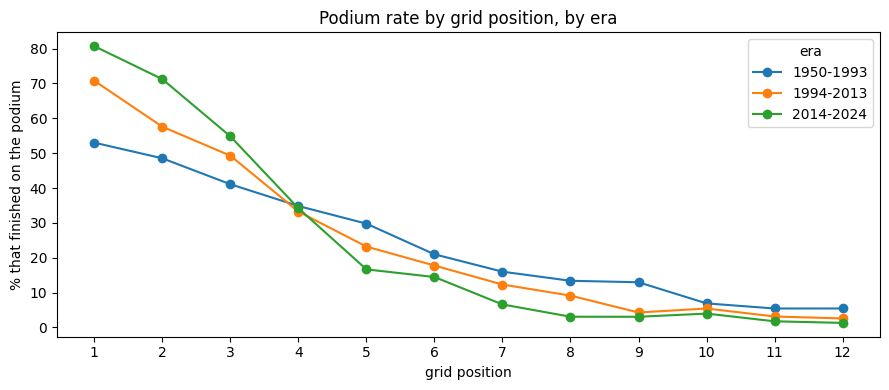

era       1950-1993  1994-2013  2014-2024
grid_pos                                 
1              53.0       70.8       80.7
2              48.5       57.6       71.2
3              41.1       49.3       54.8
5              29.8       23.2       16.7
10              6.9        5.4        4.0

Podium rate when grid_is_zero = 1: 0.0%
Features so far: ['grid_pos', 'grid_is_zero', 'field_size']


In [26]:
on_grid = m[m["grid"] > 0].groupby("raceId")["grid"].agg(field_size="size", last_grid="max")
m = m.merge(on_grid, on="raceId", how="left")
print("Races without any grid information:", int(m["field_size"].isna().sum()))

m["grid_is_zero"] = (m["grid"] == 0).astype(int)
m["grid_pos"] = np.where(m["grid"] > 0, m["grid"], m["last_grid"] + 1)

FEATURES = ["grid_pos", "grid_is_zero", "field_size"]

# Evidence: podium rate by grid position, in three eras
m["era"] = pd.cut(m["year"], bins=[1949, 1993, 2013, 2024],
                  labels=["1950-1993", "1994-2013", "2014-2024"])
on = m[(m["grid_is_zero"] == 0) & (m["grid_pos"] <= 12)]
by_era = on.groupby(["grid_pos", "era"], observed=True)["podium"].mean().unstack() * 100

by_era.plot(marker="o", figsize=(9, 4))
plt.xticks(range(1, 13))
plt.xlabel("grid position")
plt.ylabel("% that finished on the podium")
plt.title("Podium rate by grid position, by era")
plt.tight_layout()
plt.show()

print(by_era.loc[[1, 2, 3, 5, 10]].round(1))
print(f"\nPodium rate when grid_is_zero = 1: {100 * m[m['grid_is_zero'] == 1]['podium'].mean():.1f}%")
print("Features so far:", FEATURES)

In [27]:
m = m.sort_values(["year", "round", "positionOrder"]).reset_index(drop=True)

by_driver = m.groupby("driverId")

for w in [3, 5, 10]:
    m[f"drv_podium_last{w}"] = by_driver["podium"].transform(
        lambda s: s.shift(1).rolling(w, min_periods=1).mean())

m["drv_finish_last5"] = by_driver["positionOrder"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean())
m["drv_podium_career"] = by_driver["podium"].transform(
    lambda s: s.shift(1).expanding().mean())
m["drv_races_before"] = by_driver.cumcount()

# Leakage check 1: a driver's first race must have no form at all
first = m[m["drv_races_before"] == 0]
assert first[["drv_podium_last3", "drv_podium_last5", "drv_podium_last10",
              "drv_finish_last5", "drv_podium_career"]].isna().all().all()
print("Check passed: first race of every driver has empty form")

# Leakage check 2: look at one driver by eye
busiest = m["driverId"].value_counts().idxmax()
m[m["driverId"] == busiest][["year", "round", "podium", "positionOrder",
                             "drv_podium_last3", "drv_finish_last5",
                             "drv_races_before"]].head(8)

Check passed: first race of every driver has empty form


,year,round,podium,positionOrder,drv_podium_last3,drv_finish_last5,drv_races_before
16973,2001,1,0,12,NaN,NaN,0
16996,2001,2,0,13,0.0,12.000000,1
17024,2001,3,0,19,0.0,12.500000,2
17049,2001,4,0,22,0.0,14.666667,3
17062,2001,5,0,13,0.0,16.500000,4
17086,2001,6,0,15,0.0,15.800000,5
17106,2001,7,0,13,0.0,16.400000,6
17134,2001,8,0,19,0.0,16.400000,7


In [28]:
team = (m.groupby(["constructorId", "year", "round", "raceId"], as_index=False)
          .agg(team_podiums=("podium", "sum"), team_cars=("podium", "size"))
          .sort_values(["constructorId", "year", "round"]))

by_team = team.groupby("constructorId")
for w in [3, 5, 10]:
    podiums = by_team["team_podiums"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).sum())
    cars = by_team["team_cars"].transform(lambda s: s.shift(1).rolling(w, min_periods=1).sum())
    team[f"con_podium_last{w}"] = podiums / cars
team["con_races_before"] = by_team.cumcount()

rows_before = len(m)
m = m.merge(team.drop(columns=["year", "round", "team_podiums", "team_cars"]),
            on=["constructorId", "raceId"], how="left")
assert len(m) == rows_before
print("Constructor form added. Rows:", len(m))

Constructor form added. Rows: 26668


In [29]:
from sklearn.metrics import roc_auc_score

train_rows = m[m["year"] <= 2019]      # training seasons only

candidates = ["grid_pos",
              "drv_podium_last3", "drv_podium_last5", "drv_podium_last10",
              "drv_finish_last5", "drv_podium_career", "drv_races_before",
              "con_podium_last3", "con_podium_last5", "con_podium_last10",
              "con_races_before"]

rows = []
for col in candidates:
    d = train_rows[[col, "podium"]].dropna()
    auc = roc_auc_score(d["podium"], d[col])
    rows.append({"feature": col,
                 "auc_alone": round(max(auc, 1 - auc), 3),
                 "missing_%": round(100 * train_rows[col].isna().mean(), 1)})

pd.DataFrame(rows).sort_values("auc_alone", ascending=False).reset_index(drop=True)

,feature,auc_alone,missing_%
0,grid_pos,0.890,0.0
1,con_podium_last10,0.846,1.4
2,drv_podium_last10,0.838,3.5
3,con_podium_last5,0.833,1.4
4,drv_podium_last5,0.815,3.5
5,con_podium_last3,0.814,1.4
6,drv_podium_career,0.814,3.5
7,drv_finish_last5,0.807,3.5
8,drv_podium_last3,0.779,3.5
9,drv_races_before,0.668,0.0


In [30]:
FEATURES += ["drv_podium_last10", "drv_finish_last5", "drv_podium_career", "drv_races_before",
             "con_podium_last10", "con_races_before"]

# Previous race of the same season
order = clean["races"][["raceId", "year", "round"]].sort_values(["year", "round"]).copy()
order["prev_raceId"] = order.groupby("year")["raceId"].shift(1)

def standings_before(table, key, prefix):
    s = clean[table][["raceId", key, "points", "position", "wins"]].copy()
    print(f"{table}: duplicate (raceId, {key}) =", int(s.duplicated(["raceId", key]).sum()))
    leader = s.groupby("raceId")["points"].transform("max")
    s[f"{prefix}_std_points_share"] = np.where(leader > 0, s["points"] / leader, 0.0)
    s = s.rename(columns={"raceId": "prev_raceId",
                          "position": f"{prefix}_std_pos",
                          "wins": f"{prefix}_std_wins"}).drop(columns="points")
    s["prev_raceId"] = s["prev_raceId"].astype(float)
    return s

rows_before = len(m)
m = m.merge(order[["raceId", "prev_raceId"]], on="raceId", how="left")
m = m.merge(standings_before("driver_standings", "driverId", "drv"),
            on=["prev_raceId", "driverId"], how="left")
m = m.merge(standings_before("constructor_standings", "constructorId", "con"),
            on=["prev_raceId", "constructorId"], how="left")
assert len(m) == rows_before

STANDINGS = ["drv_std_pos", "drv_std_wins", "drv_std_points_share",
             "con_std_pos", "con_std_wins", "con_std_points_share"]

# Leakage check: the first race of a season must have no standings
assert m.loc[m["round"] == 1, STANDINGS].isna().all().all()
print("Check passed: round 1 of every season has empty standings")

driver_standings: duplicate (raceId, driverId) = 0
constructor_standings: duplicate (raceId, constructorId) = 0
Check passed: round 1 of every season has empty standings


In [31]:
# Real-world check: the last race of 2021
last_2021 = m[(m["year"] == 2021) & (m["round"] == m[m["year"] == 2021]["round"].max())]
display(last_2021.sort_values("drv_std_pos")[["driverId", "grid", "positionOrder", "drv_std_pos",
                                             "drv_std_wins", "drv_std_points_share"]].head(4))

def auc_table(cols):
    train_rows = m[m["year"] <= 2019]
    out = []
    for col in cols:
        d = train_rows[[col, "podium"]].dropna()
        auc = roc_auc_score(d["podium"], d[col])
        out.append({"feature": col, "auc_alone": round(max(auc, 1 - auc), 3),
                    "missing_%": round(100 * train_rows[col].isna().mean(), 1)})
    return pd.DataFrame(out).sort_values("auc_alone", ascending=False).reset_index(drop=True)

display(auc_table(STANDINGS))

tr = m[m["year"] <= 2019]
print(f"Round-1 rows in training: {100 * (tr['round'] == 1).mean():.1f}%")
print(f"Constructor standings missing before 1958: "
      f"{100 * tr[tr['year'] < 1958]['con_std_pos'].isna().mean():.1f}%")

,driverId,grid,positionOrder,drv_std_pos,drv_std_wins,drv_std_points_share
25289,830,1,1,1.0,9.0,1.000000
25290,1,2,2,2.0,8.0,1.000000
25294,822,6,6,3.0,1.0,0.589986
25303,815,4,15,4.0,1.0,0.514208


,feature,auc_alone,missing_%
0,drv_std_pos,0.845,14.5
1,con_std_points_share,0.843,14.0
2,drv_std_points_share,0.839,14.5
3,con_std_pos,0.837,14.0
4,con_std_wins,0.773,14.0
5,drv_std_wins,0.723,14.5


Round-1 rows in training: 6.6%
Constructor standings missing before 1958: 100.0%


In [32]:
q = clean["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].copy()
q["best"] = q[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
q["quali_gap_pct"] = 100 * (q["best"] / q.groupby("raceId")["best"].transform("min") - 1)
q = q.rename(columns={"position": "quali_pos"})[["raceId", "driverId", "quali_pos", "quali_gap_pct"]]

rows_before = len(m)
m = m.merge(q, on=["raceId", "driverId"], how="left")
assert len(m) == rows_before

m["has_quali"] = m["quali_pos"].notna().astype(int)
m["grid_drop"] = m["grid_pos"] - m["quali_pos"]

QUALI = ["quali_pos", "quali_gap_pct", "grid_drop", "has_quali"]

print("Share of rows with qualifying data, by period:")
print((m.groupby("period", observed=True)["has_quali"].mean() * 100).round(1).to_string())

print("\nquali_gap_pct, spread of values:")
print(m["quali_gap_pct"].describe(percentiles=[0.5, 0.95, 0.99]).round(2).to_string())

have = m[(m["has_quali"] == 1) & (m["year"] <= 2019)]
print(f"\nCorrelation of quali_pos with grid_pos (training rows): "
      f"{have['quali_pos'].corr(have['grid_pos']):.3f}")

display(auc_table(["quali_pos", "quali_gap_pct", "grid_drop"]))

Share of rows with qualifying data, by period:
period
train (<=2019)           34.1
validation (2020-21)     99.9
test (2022+)            100.0

quali_gap_pct, spread of values:
count    10338.00
mean         2.49
std          9.41
min          0.00
50%          1.84
95%          6.39
99%         12.47
max        922.86

Correlation of quali_pos with grid_pos (training rows): 0.975


,feature,auc_alone,missing_%
0,quali_pos,0.906,65.9
1,quali_gap_pct,0.887,66.5
2,grid_drop,0.544,65.9


17 features, none of them post-race
Modeling table: (26668, 26)


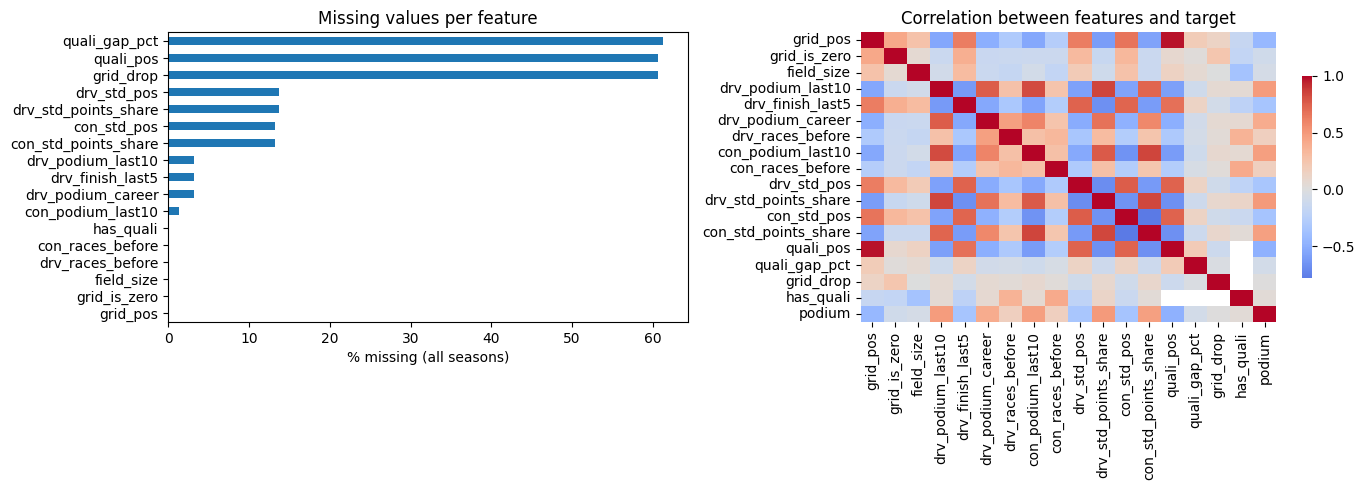

quali_pos              -0.49
grid_pos               -0.44
con_std_pos            -0.36
drv_finish_last5       -0.35
drv_std_pos            -0.34
grid_is_zero           -0.10
quali_gap_pct          -0.08
field_size             -0.06
grid_drop               0.01
has_quali               0.03
con_races_before        0.16
drv_races_before        0.16
drv_podium_career       0.40
con_std_points_share    0.46
con_podium_last10       0.47
drv_podium_last10       0.49
drv_std_points_share    0.49


In [33]:
FEATURES += ["drv_std_pos", "drv_std_points_share", "con_std_pos", "con_std_points_share"] + QUALI

GROUPS = {
    "grid": ["grid_pos", "grid_is_zero", "field_size"],
    "form": ["drv_podium_last10", "drv_finish_last5", "drv_podium_career", "drv_races_before",
             "con_podium_last10", "con_races_before"],
    "standings": ["drv_std_pos", "drv_std_points_share", "con_std_pos", "con_std_points_share"],
    "qualifying": QUALI,
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)

# Leakage check: no post-race column and no target among the features
leaks = set(FEATURES) & set(POST_RACE + [TARGET, "resultId"])
assert not leaks, f"Leaking columns: {leaks}"
print(f"{len(FEATURES)} features, none of them post-race")

ID_COLS = ["raceId", "driverId", "constructorId", "year", "round", "name",
           "non_starter", "is_indy500"]
model_table = m[ID_COLS + FEATURES + [TARGET]].copy()
assert not model_table.duplicated(["raceId", "driverId"]).any()
print("Modeling table:", model_table.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
(model_table[FEATURES].isna().mean() * 100).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_xlabel("% missing (all seasons)")
axes[0].set_title("Missing values per feature")

corr = model_table[FEATURES + [TARGET]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": 0.7})
axes[1].set_title("Correlation between features and target")
plt.tight_layout()
plt.show()

print(corr[TARGET].drop(TARGET).sort_values().round(2).to_string())

model_table.to_csv("/kaggle/working/modeling_table.csv", index=False)

### Selected features and why each is valid at the pre-race cutoff

Prediction cutoff: after qualifying, before the race start. All history features are built with `shift(1)` or a join on the previous race, so a row never sees its own race.

| Group | Feature | Meaning | Why it is known before the race |
|---|---|---|---|
| Grid | `grid_pos` | Starting position; grid 0 is placed one slot behind the last car | The grid is fixed after qualifying and penalties |
| Grid | `grid_is_zero` | 1 if the driver has no grid slot (pit-lane start or no start) | Same |
| Grid | `field_size` | Number of cars on the grid | Same |
| Form | `drv_podium_last10` | Driver's podium rate in his previous 10 races | Uses earlier races only |
| Form | `drv_finish_last5` | Driver's average finishing order in his previous 5 races | Uses earlier races only |
| Form | `drv_podium_career` | Driver's podium rate over all earlier races | Uses earlier races only |
| Form | `drv_races_before` | Number of earlier races of the driver | Count of earlier races |
| Form | `con_podium_last10` | Share of the team's car entries on the podium in its previous 10 races | Computed per team per race first, so a teammate's result in the same race is never included |
| Form | `con_races_before` | Number of earlier races of the team | Count of earlier races |
| Standings | `drv_std_pos`, `drv_std_points_share` | Driver's championship position and points as a share of the leader's, before this race | Taken from the standings after the previous race of the same season |
| Standings | `con_std_pos`, `con_std_points_share` | The same for the team | Same |
| Qualifying | `quali_pos` | Qualifying position | Qualifying takes place before the race |
| Qualifying | `quali_gap_pct` | Gap of the driver's best qualifying lap to the fastest lap, in % | Same |
| Qualifying | `grid_drop` | Grid position minus qualifying position (penalties) | Both are known before the race |
| Qualifying | `has_quali` | 1 if qualifying data exists for this row | Describes data availability |

**Evidence for the choices (training seasons 1950-2019 only):**
- Grid is the strongest single feature (AUC 0.890 alone). The podium rate from pole rose from 53.0% (1950-1993) to 80.7% (2014-2024).
- A 10-race window beats 5 and 3 races for both driver (0.838, 0.815, 0.779) and team (0.846, 0.833, 0.814), and beats the driver's career rate (0.814).
- Standings position and points share reach 0.84. Win counts were weaker (0.72 to 0.77) and were dropped.
- Points share is used instead of raw points because points systems changed across eras.

**Leakage controls:** a debut race has empty form; round 1 of each season has empty standings; before the final race of 2021 the two title contenders both have a points share of 1.0, which is only possible with pre-race standings; an assertion confirms that no post-race column is in the feature list.

**Not used:** current-race position, points, laps, status, race time, fastest lap, pit stops, lap times and post-race standings (all post-race). Sprint results are pre-race but exist only from 2021, so no training season contains them. Nationality and a home-race flag were left out because Question 2 found no home effect.

**Known limitations:** qualifying features are missing for 66% of training rows but almost none of the validation and test rows; constructor standings do not exist before 1958; form and standings features are strongly correlated with each other.

# 7. Train, validation and test split

Rows: 26668 -> 24586 (removed 1701 non-starters and 381 Indianapolis 500 rows)


,set,seasons,races,rows,podiums,podium_%,has_quali_%,share_of_rows_%
0,train,1950-2019,1007,22459,3038,13.5,36.9,91.3
1,validation,2020-2021,39,775,117,15.1,99.9,3.2
2,test,2022-2024,68,1352,204,15.1,100.0,5.5


Training set: 19421 non-podium rows for 3038 podium rows (about 6.4 to 1)


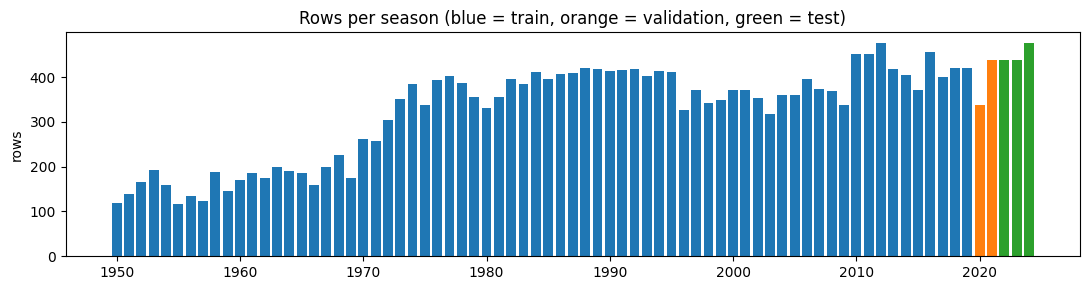

In [34]:
pop = model_table[~model_table["non_starter"] & ~model_table["is_indy500"]].copy()
print(f"Rows: {len(model_table)} -> {len(pop)} "
      f"(removed {int(model_table['non_starter'].sum())} non-starters and "
      f"{int((model_table['is_indy500'] & ~model_table['non_starter']).sum())} Indianapolis 500 rows)")

train = pop[pop["year"] <= 2019]
val = pop[(pop["year"] >= 2020) & (pop["year"] <= 2021)]
test = pop[pop["year"] >= 2022]

# The sets must not share any race, and must be in time order
assert not set(train["raceId"]) & set(val["raceId"])
assert not set(val["raceId"]) & set(test["raceId"])
assert train["year"].max() < val["year"].min() <= val["year"].max() < test["year"].min()

rows = []
for label, d in [("train", train), ("validation", val), ("test", test)]:
    rows.append({"set": label,
                 "seasons": f"{d['year'].min()}-{d['year'].max()}",
                 "races": d["raceId"].nunique(),
                 "rows": len(d),
                 "podiums": int(d["podium"].sum()),
                 "podium_%": round(100 * d["podium"].mean(), 1),
                 "has_quali_%": round(100 * d["has_quali"].mean(), 1),
                 "share_of_rows_%": round(100 * len(d) / len(pop), 1)})
display(pd.DataFrame(rows))

neg, pos = (train["podium"] == 0).sum(), (train["podium"] == 1).sum()
print(f"Training set: {neg} non-podium rows for {pos} podium rows "
      f"(about {neg / pos:.1f} to 1)")

per_year = pop.groupby("year").size()
colors = ["tab:blue" if y <= 2019 else "tab:orange" if y <= 2021 else "tab:green"
          for y in per_year.index]
plt.figure(figsize=(11, 3))
plt.bar(per_year.index, per_year.values, color=colors)
plt.ylabel("rows")
plt.title("Rows per season (blue = train, orange = validation, green = test)")
plt.tight_layout()
plt.show()

### Split design and justification

| Set | Seasons | Races | Rows | Podium rate |
|---|---|---|---|---|
| Train | 1950-2019 | 1,007 | 22,459 | 13.5% |
| Validation | 2020-2021 | 39 | 775 | 15.1% |
| Test | 2022-2024 | 68 | 1,352 | 15.1% |

**Why a split by season.** The task is to predict a race from information available before it. A random split would train on races that happen after the ones being tested, and would separate drivers of the same race across sets although a race has only three podium places. Both would leak future information. Assertions confirm that no race appears in two sets and that the sets are in time order.

**Role of each set.** Training is used to fit models. Validation (the two seasons closest to the test period) is used to compare models and to choose hyperparameters, the training window and the probability threshold. The test set is used once, at the end.

**Rows removed (from 26,668 to 24,586).**
- 1,701 non-starters (codes F and W: failed to qualify or withdrawn). Both are known before the race start. Only 12 of them fall in validation and test, so this mainly affects training, where it raises the podium rate from 12.5% to 13.5%.
- 381 Indianapolis 500 rows (1950-1960). Its field was almost entirely separate from the rest of the championship.

**Known limitations.** Training is 91% of the rows because 70 seasons precede the validation period. Validation has only 117 podiums, so small metric differences are not meaningful. Training differs from the later sets in podium rate (13.5% vs 15.1%) and qualifying coverage (36.9% vs about 100%); the training-window experiment below addresses this.

# 8. Preprocessing and baseline

model,baseline: grid only,gradient boosting,logistic regression
train_from,,,
1950,0.648,0.740,0.733
1994,0.648,0.732,0.724
2003,0.648,0.708,0.728
2014,0.648,0.694,0.720


model,baseline: grid only,gradient boosting,logistic regression
train_from,,,
1950,0.91,0.936,0.930
1994,0.91,0.928,0.929
2003,0.91,0.929,0.929
2014,0.91,0.917,0.927


,train_from,train_rows,train_podium_%
0,1950,22459,13.5
3,1994,10093,14.0
6,2003,6783,14.2
9,2014,2471,14.7


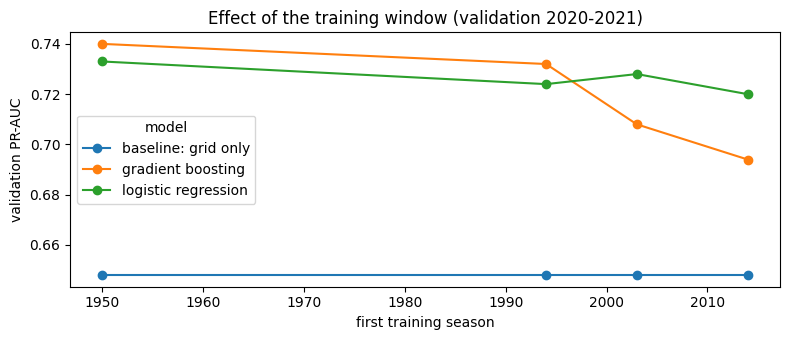

In [35]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

def get_xy(df, cap):
    X = df[FEATURES].copy()
    X["quali_gap_pct"] = X["quali_gap_pct"].clip(upper=cap)
    return X, df[TARGET]

def make_logreg():
    return make_pipeline(SimpleImputer(strategy="median"),
                         StandardScaler(),
                         LogisticRegression(max_iter=1000))

MODELS = {
    "baseline: grid only": (["grid_pos"], make_logreg),
    "logistic regression": (FEATURES, make_logreg),
    "gradient boosting": (FEATURES, lambda: HistGradientBoostingClassifier(random_state=42)),
}

rows = []
for start in [1950, 1994, 2003, 2014]:
    tr = train[train["year"] >= start]
    cap = tr["quali_gap_pct"].quantile(0.99)          # learned from training rows only
    X_tr, y_tr = get_xy(tr, cap)
    X_va, y_va = get_xy(val, cap)
    for name, (cols, make) in MODELS.items():
        model = make().fit(X_tr[cols], y_tr)
        p = model.predict_proba(X_va[cols])[:, 1]
        rows.append({"train_from": start, "train_rows": len(tr),
                     "train_podium_%": round(100 * y_tr.mean(), 1),
                     "model": name,
                     "val_PR_AUC": round(average_precision_score(y_va, p), 3),
                     "val_ROC_AUC": round(roc_auc_score(y_va, p), 3)})

window = pd.DataFrame(rows)
display(window.pivot(index="train_from", columns="model", values="val_PR_AUC"))
display(window.pivot(index="train_from", columns="model", values="val_ROC_AUC"))
display(window.drop_duplicates("train_from")[["train_from", "train_rows", "train_podium_%"]])

window.pivot(index="train_from", columns="model", values="val_PR_AUC").plot(
    marker="o", figsize=(8, 3.5))
plt.xlabel("first training season")
plt.ylabel("validation PR-AUC")
plt.title("Effect of the training window (validation 2020-2021)")
plt.tight_layout()
plt.show()

### Training-window experiment

**Question.** Old seasons differ from the test era (pole converts 53% of the time before 1994 against 81% from 2014; qualifying data covers 37% of training rows against ~100% of validation and test). Does training only on recent seasons help?

**Method.** Same features and preprocessing; four training windows (from 1950, 1994, 2003, 2014); every model scored on validation (2020-2021). The test set was not used.

| First season | Rows | Baseline (grid) | Logistic regression | Gradient boosting |
|---|---|---|---|---|
| 1950 | 22,459 | 0.648 | 0.733 | 0.740 |
| 1994 | 10,093 | 0.648 | 0.724 | 0.732 |
| 2003 | 6,783 | 0.648 | 0.728 | 0.708 |
| 2014 | 2,471 | 0.648 | 0.720 | 0.694 |

(validation PR-AUC; ROC-AUC shows the same pattern, 0.936 vs 0.917 for gradient boosting.)

**Result.** Shorter windows never helped. Gradient boosting lost most (0.740 to 0.694), because it needs many rows to learn its rules; logistic regression was almost flat. The baseline is identical in every window because with one feature its ranking of drivers is always the same, and PR-AUC and ROC-AUC depend only on that ranking.

**Decision.** All models train on 1950-2019. The gap between 1950 and 1994 is below 0.01, within the noise of a validation set with 117 podiums, so we also prefer the larger window on that ground.

**Baseline.** Logistic regression on grid position alone (validation PR-AUC 0.648, ROC-AUC 0.910, against 0.151 for a random ranking). Every other model must beat it.

# 9. Models

In [36]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

# One cap, learned from the training rows only, applied to all three sets
cap = train["quali_gap_pct"].quantile(0.99)
X_tr, y_tr = get_xy(train, cap)
X_va, y_va = get_xy(val, cap)
X_te, y_te = get_xy(test, cap)        # prepared now, used only at the very end

def best_threshold(y, p):
    thresholds = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y, (p >= t).astype(int)) for t in thresholds]
    i = int(np.argmax(f1s))
    return round(thresholds[i], 2), f1s[i]

candidates = []
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, "balanced"]:
        candidates.append(("logistic regression", f"C={C}, class_weight={cw}",
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=C, class_weight=cw, max_iter=2000))))

for lr in [0.05, 0.1]:
    for leaves in [15, 31]:
        for cw in [None, "balanced"]:
            candidates.append(("gradient boosting",
                f"learning_rate={lr}, max_leaf_nodes={leaves}, class_weight={cw}",
                HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves,
                    max_iter=300, class_weight=cw, early_stopping=True, random_state=42)))

for hidden in [(16,), (32,), (32, 16)]:
    for alpha in [0.0001, 0.01]:
        candidates.append(("neural network", f"hidden={hidden}, alpha={alpha}",
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha,
                                        early_stopping=True, max_iter=500, random_state=42))))

rows, fitted = [], {}
for family, settings, model in candidates:
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_va)[:, 1]
    thr, f1_best = best_threshold(y_va, p)
    rows.append({"model": family, "settings": settings,
                 "val_PR_AUC": average_precision_score(y_va, p),
                 "val_ROC_AUC": roc_auc_score(y_va, p),
                 "val_F1_at_0.5": f1_score(y_va, (p >= 0.5).astype(int)),
                 "best_threshold": thr,
                 "val_F1_best": f1_best})
    fitted[(family, settings)] = model

tuning = pd.DataFrame(rows).round(3)
display(tuning.sort_values(["model", "val_PR_AUC"], ascending=[True, False]).reset_index(drop=True))

# Before/after: the effect of class weights
cw = tuning[tuning["model"] != "neural network"].copy()
cw["class_weight"] = cw["settings"].str.extract(r"class_weight=(\w+)", expand=False)
print("Best validation score with and without class weights:")
display(cw.groupby(["model", "class_weight"])[["val_PR_AUC", "val_F1_at_0.5", "val_F1_best"]].max())

# The chosen setting per model: highest validation PR-AUC
best = tuning.loc[tuning.groupby("model")["val_PR_AUC"].idxmax()].reset_index(drop=True)
print("Chosen settings:")
display(best)

,model,settings,val_PR_AUC,val_ROC_AUC,val_F1_at_0.5,best_threshold,val_F1_best
0,gradient boosting,"learning_rate=0.05, max_leaf_nodes=31, class_w...",0.742,0.935,0.682,0.34,0.717
1,gradient boosting,"learning_rate=0.1, max_leaf_nodes=31, class_we...",0.740,0.936,0.676,0.34,0.708
2,gradient boosting,"learning_rate=0.05, max_leaf_nodes=15, class_w...",0.738,0.932,0.670,0.36,0.712
3,gradient boosting,"learning_rate=0.1, max_leaf_nodes=15, class_we...",0.731,0.931,0.688,0.78,0.716
4,gradient boosting,"learning_rate=0.05, max_leaf_nodes=31, class_w...",0.725,0.932,0.684,0.45,0.710
5,gradient boosting,"learning_rate=0.1, max_leaf_nodes=31, class_we...",0.718,0.932,0.707,0.46,0.716
6,gradient boosting,"learning_rate=0.1, max_leaf_nodes=15, class_we...",0.709,0.928,0.679,0.35,0.718
7,gradient boosting,"learning_rate=0.05, max_leaf_nodes=15, class_w...",0.691,0.929,0.698,0.48,0.707
8,logistic regression,"C=1, class_weight=None",0.733,0.930,0.673,0.37,0.703
9,logistic regression,"C=10, class_weight=None",0.733,0.930,0.673,0.37,0.703


Best validation score with and without class weights:


val_PR_AUC  val_F1_at_0.5  val_F1_best
model               class_weight                                        
gradient boosting   None               0.742          0.682        0.718
                    balanced           0.731          0.707        0.716
logistic regression None               0.733          0.685        0.703
                    balanced           0.726          0.650        0.708

Chosen settings:


,model,settings,val_PR_AUC,val_ROC_AUC,val_F1_at_0.5,best_threshold,val_F1_best
0,gradient boosting,"learning_rate=0.05, max_leaf_nodes=31, class_w...",0.742,0.935,0.682,0.34,0.717
1,logistic regression,"C=1, class_weight=None",0.733,0.930,0.673,0.37,0.703
2,neural network,"hidden=(32, 16), alpha=0.01",0.739,0.930,0.688,0.32,0.697


### Model tuning and selection (validation 2020-2021 only)

**Models.**
- *Logistic regression:* a weighted sum of the features turned into a probability. Simple and interpretable, but only linear effects.
- *Gradient boosting (HistGradientBoosting):* a sequence of small decision trees, each correcting the errors of the previous ones. Learns feature interactions and handles missing values natively.
- *Shallow neural network (MLP, scikit-learn):* one or two hidden layers of units that combine the features non-linearly.

All three use the same rows (train 1950-2019) and the same 17 features. Imputation medians, scaling and the cap on `quali_gap_pct` are learned from training rows only.

**Search (22 candidates).** Logistic regression: C in {0.01, 0.1, 1, 10}. Gradient boosting: learning rate in {0.05, 0.1}, max leaves in {15, 31}, early stopping on a 10% slice of the training rows. Neural network: hidden layers in {(16), (32), (32, 16)}, alpha in {0.0001, 0.01}, early stopping. Linear models and boosting were also tried with and without class weights. Each model's setting was chosen by validation PR-AUC; the F1 threshold was then chosen on validation (grid 0.05-0.95).

**Findings.**
- Without early stopping, gradient boosting overfit (best 0.730, below the untuned default at 0.740). With early stopping it reached 0.742, and larger trees became the best setting.
- Logistic regression was insensitive to C (0.731-0.733): with 22,000 rows and 17 features it does not overfit.
- The neural network needed at least 32 units (16 units: 0.667-0.686; 32 or more: 0.733-0.739).
- **Class weights (balancing experiment):** they lowered PR-AUC slightly (gradient boosting 0.742 vs 0.731; logistic regression 0.733 vs 0.726) and left the best F1 almost unchanged. Weighted models simply needed a higher threshold (about 0.75 instead of 0.2-0.4). Threshold tuning does the same job, so class weights were not used, which also keeps the outputs closer to real probabilities.
- Best thresholds are below 0.5 because podiums are rare (15%): many real podium finishers receive probabilities between 0.25 and 0.45.

| Model | Val PR-AUC | Val ROC-AUC | Threshold | Val F1 |
|---|---|---|---|---|
| Gradient boosting | 0.742 | 0.935 | 0.34 | 0.717 |
| Neural network | 0.739 | 0.930 | 0.32 | 0.697 |
| Logistic regression | 0.733 | 0.930 | 0.37 | 0.703 |
| Baseline (grid only) | 0.648 | 0.910 | | |

**Selected model: gradient boosting**, chosen on validation before any test evaluation. All three models beat the baseline by about 0.09 PR-AUC, but differ from each other by at most 0.009, which is within the noise of a validation set with 117 podiums. Validation F1 is slightly optimistic because the threshold was tuned on the same seasons.

,model,set,threshold,ROC_AUC,PR_AUC,F1,precision,recall
0,gradient boosting,train,0.34,0.938,0.685,0.650,0.589,0.724
1,neural network,train,0.32,0.906,0.590,0.593,0.512,0.705
2,logistic regression,train,0.37,0.901,0.575,0.575,0.564,0.586
3,baseline: grid only,train,0.36,0.883,0.500,0.544,0.547,0.541
4,gradient boosting,validation,0.34,0.935,0.742,0.717,0.708,0.726
5,neural network,validation,0.32,0.930,0.739,0.697,0.677,0.718
6,logistic regression,validation,0.37,0.930,0.733,0.703,0.689,0.718
7,baseline: grid only,validation,0.36,0.910,0.648,0.695,0.698,0.692
8,logistic regression,test,0.37,0.936,0.720,0.688,0.651,0.730
9,gradient boosting,test,0.34,0.938,0.701,0.679,0.638,0.725


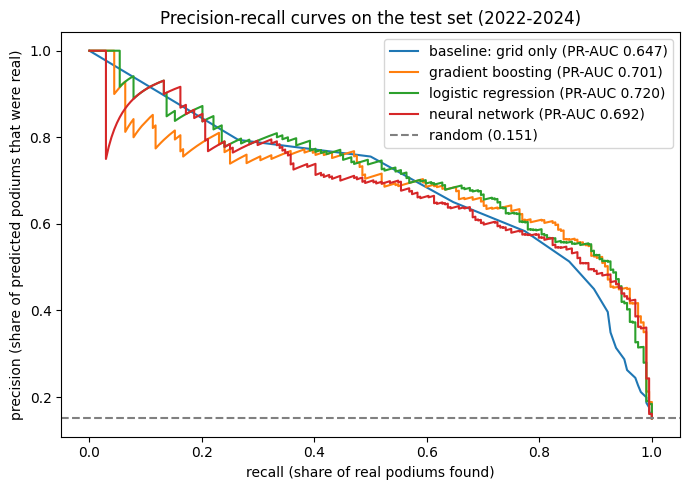

In [37]:
from sklearn.metrics import precision_recall_curve

# The four final models
baseline = make_logreg().fit(X_tr[["grid_pos"]], y_tr)
final = {"baseline: grid only": (baseline, ["grid_pos"])}
for _, row in best.iterrows():
    final[row["model"]] = (fitted[(row["model"], row["settings"])], FEATURES)

def evaluate(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, p),
            "PR_AUC": average_precision_score(y, p),
            "F1": f1_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred)}

rows, test_probs = [], {}
for name, (model, cols) in final.items():
    thr, _ = best_threshold(y_va, model.predict_proba(X_va[cols])[:, 1])   # validation only
    for split, X, y in [("train", X_tr, y_tr), ("validation", X_va, y_va), ("test", X_te, y_te)]:
        p = model.predict_proba(X[cols])[:, 1]
        rows.append({"model": name, "set": split, "threshold": thr, **evaluate(y, p, thr)})
        if split == "test":
            test_probs[name] = p

results = pd.DataFrame(rows).round(3)
results["set"] = pd.Categorical(results["set"], ["train", "validation", "test"])
display(results.sort_values(["set", "PR_AUC"], ascending=[True, False]).reset_index(drop=True))

# Precision-recall curves on the test set
plt.figure(figsize=(7, 5))
for name, p in test_probs.items():
    prec, rec, _ = precision_recall_curve(y_te, p)
    plt.plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y_te, p):.3f})")
plt.axhline(y_te.mean(), linestyle="--", color="gray", label=f"random ({y_te.mean():.3f})")
plt.xlabel("recall (share of real podiums found)")
plt.ylabel("precision (share of predicted podiums that were real)")
plt.title("Precision-recall curves on the test set (2022-2024)")
plt.legend()
plt.tight_layout()
plt.show()

### Model comparison: all five metrics

Thresholds were chosen on validation and applied unchanged to train and test. The selected model (gradient boosting) was fixed before the test set was scored.

| Model | Set | ROC-AUC | PR-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|---|
| Logistic regression | test | 0.936 | 0.720 | 0.688 | 0.651 | 0.730 |
| Gradient boosting (selected) | test | 0.938 | 0.701 | 0.679 | 0.638 | 0.725 |
| Neural network | test | 0.932 | 0.692 | 0.655 | 0.597 | 0.725 |
| Baseline (grid only) | test | 0.913 | 0.647 | 0.649 | 0.650 | 0.647 |
| Gradient boosting | validation | 0.935 | 0.742 | 0.717 | 0.708 | 0.726 |
| Gradient boosting | train | 0.938 | 0.685 | 0.650 | 0.589 | 0.724 |

(Full table for all models and sets above.)

**Metric choice.** PR-AUC is the primary metric because podiums are rare (15%) and it focuses on how well true podium finishers are ranked at the top. ROC-AUC measures overall separation. F1, precision and recall describe the yes/no decision at the chosen threshold. Accuracy is not used: always predicting "no podium" would score 85%.

**Findings.**
- All three models beat the grid-only baseline on every test metric (PR-AUC +0.05 to +0.07). The precision-recall curves show where: the baseline matches the models on the safest picks (front-row starters) but falls away beyond recall 0.7, where the models still find podium finishers who start further back.
- In an average race, gradient boosting flags about 3.4 drivers and 2.2 of them finish on the podium, against about 1.9 for the baseline (the top three on the grid).
- The validation ranking (gradient boosting first, all within 0.009) did not hold on test, where logistic regression was best by 0.019. We kept the model selected on validation. No reliable winner exists among the three; the simplest model generalised slightly better.
- **Train scores are lower than test scores for every model, including the baseline (0.500 vs 0.647).** This reflects older seasons being harder to predict, not underfitting. Gradient boosting has a much higher train score than the other models (0.685 vs 0.575-0.590) without a matching test advantage, indicating it fits the training seasons more closely.
- **Era sensitivity.** From validation to test, the baseline is unchanged (0.648 to 0.647) while the feature-based models drop (logistic regression -0.013, gradient boosting -0.041, neural network -0.047). A plausible cause is the 2022 regulation change, after which form features built on 2021 results were temporarily misleading. Recall carried over (about 0.725), but precision fell (gradient boosting 0.708 to 0.638).

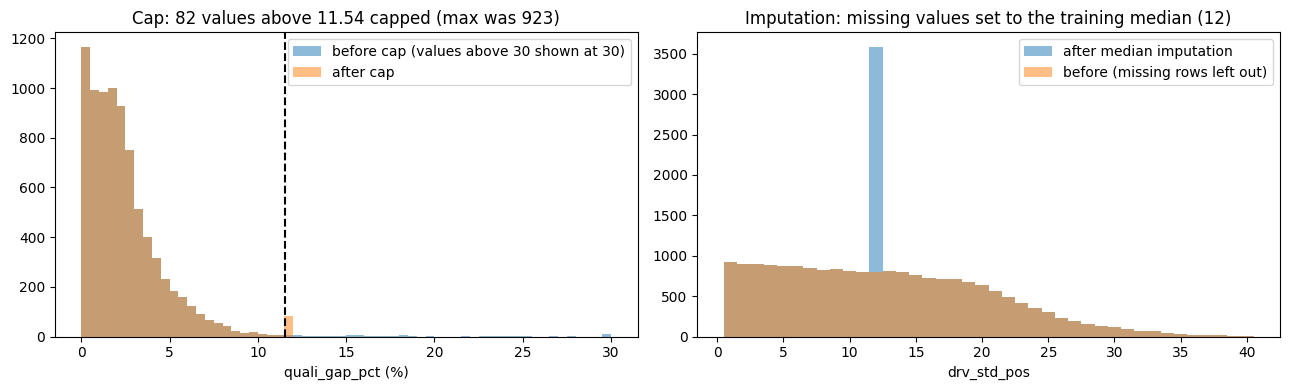

,missing_%,min,max,mean_before,std_before,mean_after,std_after
grid_pos,0.00,1.0,34.00,11.92,6.82,0.0,1.0
grid_is_zero,0.00,0.0,1.00,0.00,0.04,-0.0,1.0
field_size,0.00,10.0,34.00,22.84,3.02,-0.0,1.0
drv_podium_last10,2.56,0.0,1.00,0.14,0.21,0.0,1.0
drv_finish_last5,2.56,1.0,35.80,12.21,4.92,-0.0,1.0
drv_podium_career,2.56,0.0,1.00,0.12,0.16,-0.0,1.0
drv_races_before,0.00,0.0,325.00,63.25,62.01,0.0,1.0
con_podium_last10,1.03,0.0,1.00,0.13,0.19,0.0,1.0
con_races_before,0.00,0.0,992.00,175.18,203.56,0.0,1.0
drv_std_pos,12.38,1.0,102.00,13.07,9.17,0.0,1.0


In [38]:
pre = final["logistic regression"][0][:-1]          # imputer + scaler, fitted on training rows only
X_tr_imp = pd.DataFrame(pre[0].transform(X_tr), columns=FEATURES, index=X_tr.index)
X_tr_scaled = pd.DataFrame(pre.transform(X_tr), columns=FEATURES, index=X_tr.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 1) Capping quali_gap_pct
g = train["quali_gap_pct"].dropna()
bins = np.linspace(0, 30, 61)
axes[0].hist(g.clip(upper=30), bins=bins, alpha=0.5, label="before cap (values above 30 shown at 30)")
axes[0].hist(g.clip(upper=cap), bins=bins, alpha=0.5, label="after cap")
axes[0].axvline(cap, color="black", linestyle="--")
axes[0].set_xlabel("quali_gap_pct (%)")
axes[0].set_title(f"Cap: {int((g > cap).sum())} values above {cap:.2f} capped (max was {g.max():.0f})")
axes[0].legend()

# 2) Median imputation of drv_std_pos (14.5% missing)
bins = np.arange(0.5, 41.5, 1)
axes[1].hist(X_tr_imp["drv_std_pos"], bins=bins, alpha=0.5, label="after median imputation")
axes[1].hist(train["drv_std_pos"].dropna(), bins=bins, alpha=0.5, label="before (missing rows left out)")
axes[1].set_xlabel("drv_std_pos")
axes[1].set_title(f"Imputation: missing values set to the training median "
                  f"({pre[0].statistics_[FEATURES.index('drv_std_pos')]:.0f})")
axes[1].legend()

plt.tight_layout()
plt.show()

# 3) Scaling: every feature ends with mean 0 and standard deviation 1
stats = pd.DataFrame({"missing_%": X_tr.isna().mean() * 100,
                      "min": X_tr.min(), "max": X_tr.max(),
                      "mean_before": X_tr.mean(), "std_before": X_tr.std(),
                      "mean_after": X_tr_scaled.mean(), "std_after": X_tr_scaled.std()})
display(stats.round(2))

### Effect of preprocessing on the data (training rows, fitted on training only)

This check sits here because it inspects the preprocessing pipelines fitted in this section.

**Cap on `quali_gap_pct` (all models).** 82 values above the 99th percentile (11.54%) were capped; the maximum was 923%, a broken lap rather than real pace. Below the cap the distribution is unchanged.

**Median imputation (logistic regression and neural network).** Missing values are replaced by the training median. For `drv_std_pos` (12.4% missing, mostly round 1 of each season) this puts about 2,780 rows at position 12, creating a spike in the distribution: a reigning champion at round 1 looks like a mid-field driver. Gradient boosting does not use imputation and handles missing values natively. A possible improvement would be to fill round 1 with the previous season's final standings.

**Standard scaling (logistic regression and neural network).** Before scaling, feature spreads ranged from 0.04 (`grid_is_zero`) and 0.21 (`drv_podium_last10`) to 203.6 (`con_races_before`). After scaling, every feature has mean 0 and standard deviation 1. This makes logistic regression's regularisation treat all features equally and helps the neural network train. Tree models are unaffected by scale.

### Model limitations

- **Logistic regression:** each feature has a single straight-line effect, so it cannot learn interactions (for example, a strong team starting at the back) unless they are built by hand. It needs imputation and scaling, and its regularisation strength C made no difference.
- **Gradient boosting:** overfits without early stopping (validation PR-AUC 0.730 vs 0.742 with it). It fits the training seasons much more closely than the other models (train PR-AUC 0.685 vs 0.575 for logistic regression) without a matching test advantage, and lost the most from validation to test after the neural network (-0.041).
- **Neural network:** sensitive to small changes in its inputs and training (its score moved by 0.007 in preprocessing-order Experiment 1), has no class-weight option, is the hardest to interpret, and dropped most on test (-0.047).
- **All models:**
  - Each driver is predicted independently, so the probabilities in a race are not forced to add up to 3 podium places.
  - Only pre-race information is used, so weather, safety cars, collisions and failures are invisible to the model (see the local explanations in Section 11).
  - Most training rows come from older seasons; after the 2022 regulation change, precision fell (era sensitivity).
  - Probability calibration was not evaluated.

# 10. Experiments

,model,removed_group,n_features,val_PR_AUC,val_ROC_AUC,test_PR_AUC (info),val_drop,test_drop (info)
0,gradient boosting,none,17,0.742,0.935,0.701,0.000,0.000
1,logistic regression,none,17,0.733,0.930,0.720,0.000,0.000
2,gradient boosting,grid,14,0.709,0.926,0.646,0.033,0.054
3,logistic regression,grid,14,0.724,0.927,0.701,0.008,0.019
4,gradient boosting,form,11,0.737,0.928,0.692,0.005,0.009
5,logistic regression,form,11,0.729,0.928,0.704,0.004,0.016
6,gradient boosting,standings,13,0.738,0.931,0.666,0.004,0.035
7,logistic regression,standings,13,0.729,0.929,0.721,0.003,-0.001
8,gradient boosting,qualifying,13,0.735,0.930,0.725,0.007,-0.024
9,logistic regression,qualifying,13,0.722,0.925,0.715,0.010,0.005


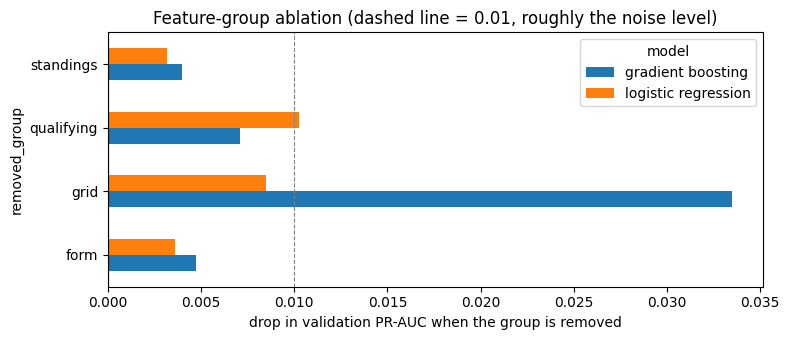

In [39]:
from sklearn.base import clone

templates = {"gradient boosting": final["gradient boosting"][0],
             "logistic regression": final["logistic regression"][0]}

rows = []
for removed in ["none"] + list(GROUPS):
    cols = FEATURES if removed == "none" else [f for f in FEATURES if f not in GROUPS[removed]]
    for name, template in templates.items():
        model = clone(template).fit(X_tr[cols], y_tr)
        rows.append({"model": name, "removed_group": removed, "n_features": len(cols),
                     "val_PR_AUC": average_precision_score(y_va, model.predict_proba(X_va[cols])[:, 1]),
                     "val_ROC_AUC": roc_auc_score(y_va, model.predict_proba(X_va[cols])[:, 1]),
                     "test_PR_AUC (info)": average_precision_score(y_te, model.predict_proba(X_te[cols])[:, 1])})

abl = pd.DataFrame(rows)
full = abl[abl["removed_group"] == "none"].set_index("model")
abl["val_drop"] = abl["model"].map(full["val_PR_AUC"]) - abl["val_PR_AUC"]
abl["test_drop (info)"] = abl["model"].map(full["test_PR_AUC (info)"]) - abl["test_PR_AUC (info)"]
display(abl.round(3))

plot = abl[abl["removed_group"] != "none"].pivot(index="removed_group", columns="model", values="val_drop")
plot.plot(kind="barh", figsize=(8, 3.5))
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(0.01, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("drop in validation PR-AUC when the group is removed")
plt.title("Feature-group ablation (dashed line = 0.01, roughly the noise level)")
plt.tight_layout()
plt.show()

### Feature-group ablation

Each group was removed in turn and the model retrained with the selected settings. The validation drop is the result; test is shown for information only and was not used for any decision.

| Group removed | GB val drop | LR val drop | GB test drop (info) | LR test drop (info) |
|---|---|---|---|---|
| Grid (3 features) | 0.033 | 0.008 | 0.054 | 0.019 |
| Qualifying (4) | 0.007 | 0.010 | -0.024 | 0.005 |
| Form (6) | 0.005 | 0.004 | 0.009 | 0.016 |
| Standings (4) | 0.004 | 0.003 | 0.035 | -0.001 |

(drop in PR-AUC; full models: GB 0.742 val / 0.701 test, LR 0.733 / 0.720)

**Findings.**
- **Grid is the only group whose removal clearly exceeds the noise level** (about 0.01 on a validation set with 117 podiums). Without it, gradient boosting falls to 0.646 on test, the level of the grid-only baseline.
- **Logistic regression loses little without grid** because qualifying position stands in for it (correlation 0.975; qualifying covers about 100% of validation and test rows). Gradient boosting does not compensate as well.
- **Form, standings and qualifying each cost at most 0.010 when removed alone**, although together they raise PR-AUC from 0.648 (grid only) to about 0.74. They overlap strongly (form and standings both describe current competitiveness), so one-at-a-time ablation understates their joint value.
- Small effects are not consistent between validation and test (e.g. removing qualifying improves gradient boosting on test by 0.024), so they are treated as noise.

**Decision.** All 17 features are kept: no group lowered validation performance.

**Comparison with the pre-training evidence.** The single-feature AUCs ranked grid first (0.890), followed by form and standings (about 0.84). Ablation confirms grid as the most important group, and shows that the others are strong individually but largely interchangeable.

In [40]:
# The wrong order: preprocessing learned from ALL rows (train + validation + test)
cap_all = pop["quali_gap_pct"].quantile(0.99)
X_all, _ = get_xy(pop, cap_all)
imp_all = SimpleImputer(strategy="median").fit(X_all)
sc_all = StandardScaler().fit(imp_all.transform(X_all))

def prep_leaky(df):
    X, _ = get_xy(df, cap_all)
    return sc_all.transform(imp_all.transform(X))

rows = []
for name in ["logistic regression", "neural network"]:
    correct = final[name][0]                          # pipeline fitted on train only
    leaky = clone(correct[-1]).fit(prep_leaky(train), y_tr)
    for order, p_va, p_te in [
        ("split, then fit preprocessing (ours)",
         correct.predict_proba(X_va)[:, 1], correct.predict_proba(X_te)[:, 1]),
        ("fit preprocessing on all rows, then split",
         leaky.predict_proba(prep_leaky(val))[:, 1], leaky.predict_proba(prep_leaky(test))[:, 1])]:
        rows.append({"model": name, "order": order,
                     "val_PR_AUC": average_precision_score(y_va, p_va),
                     "val_ROC_AUC": roc_auc_score(y_va, p_va),
                     "test_PR_AUC (info)": average_precision_score(y_te, p_te)})
display(pd.DataFrame(rows).round(4))

# What actually leaked: the learned medians
medians = pd.DataFrame({
    "median, train rows only": final["logistic regression"][0][0].statistics_,
    "median, all rows": imp_all.statistics_}, index=FEATURES)
print(f"Cap on quali_gap_pct: train only {cap:.2f} | all rows {cap_all:.2f}")
display(medians[medians.iloc[:, 0] != medians.iloc[:, 1]].round(3))

,model,order,val_PR_AUC,val_ROC_AUC,test_PR_AUC (info)
0,logistic regression,"split, then fit preprocessing (ours)",0.7326,0.9296,0.7200
1,logistic regression,"fit preprocessing on all rows, then split",0.7328,0.9296,0.7200
2,neural network,"split, then fit preprocessing (ours)",0.7392,0.9299,0.6920
3,neural network,"fit preprocessing on all rows, then split",0.7326,0.9268,0.6844


Cap on quali_gap_pct: train only 11.54 | all rows 12.45


,"median, train rows only","median, all rows"
drv_races_before,43.000,48.000
con_races_before,96.000,103.000
drv_std_points_share,0.079,0.083
con_std_points_share,0.140,0.143
quali_gap_pct,1.961,1.836


In [41]:
FORM = GROUPS["form"]

# The other order: remove rows first, then compute the form features
alt = (m[~m["non_starter"] & ~m["is_indy500"]]
       .drop(columns=FORM)
       .sort_values(["year", "round", "positionOrder"])
       .reset_index(drop=True))

g = alt.groupby("driverId")
alt["drv_podium_last10"] = g["podium"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
alt["drv_finish_last5"] = g["positionOrder"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
alt["drv_podium_career"] = g["podium"].transform(lambda s: s.shift(1).expanding().mean())
alt["drv_races_before"] = g.cumcount()

t = (alt.groupby(["constructorId", "year", "round", "raceId"], as_index=False)
        .agg(team_podiums=("podium", "sum"), team_cars=("podium", "size"))
        .sort_values(["constructorId", "year", "round"]))
gt = t.groupby("constructorId")
t["con_podium_last10"] = (gt["team_podiums"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
                          / gt["team_cars"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum()))
t["con_races_before"] = gt.cumcount()
alt = alt.merge(t[["constructorId", "raceId", "con_podium_last10", "con_races_before"]],
                on=["constructorId", "raceId"], how="left")
assert len(alt) == len(pop)

# How different are the features?
cmp = pop[["raceId", "driverId"] + FORM].merge(alt[["raceId", "driverId"] + FORM],
                                               on=["raceId", "driverId"], suffixes=("", "_alt"))
changed = {f: round(100 * (~np.isclose(cmp[f], cmp[f + "_alt"], equal_nan=True)).mean(), 1) for f in FORM}
print("% of rows whose value changes:", changed)

# Same split, same settings, retrain and compare
a_tr, a_va, a_te = alt[alt["year"] <= 2019], alt[alt["year"].between(2020, 2021)], alt[alt["year"] >= 2022]
cap_alt = a_tr["quali_gap_pct"].quantile(0.99)
Xa_tr, ya_tr = get_xy(a_tr, cap_alt)
Xa_va, ya_va = get_xy(a_va, cap_alt)
Xa_te, ya_te = get_xy(a_te, cap_alt)

rows = []
for name in ["gradient boosting", "logistic regression"]:
    ours = final[name][0]
    other = clone(ours).fit(Xa_tr, ya_tr)
    for order, mdl, Xv, yv, Xt, yt in [
        ("features first, then remove rows (ours)", ours, X_va, y_va, X_te, y_te),
        ("remove rows first, then features", other, Xa_va, ya_va, Xa_te, ya_te)]:
        p_va = mdl.predict_proba(Xv)[:, 1]
        rows.append({"model": name, "order": order,
                     "val_PR_AUC": average_precision_score(yv, p_va),
                     "val_ROC_AUC": roc_auc_score(yv, p_va),
                     "test_PR_AUC (info)": average_precision_score(yt, mdl.predict_proba(Xt)[:, 1])})
display(pd.DataFrame(rows).round(4))

% of rows whose value changes: {'drv_podium_last10': np.float64(1.9), 'drv_finish_last5': np.float64(10.9), 'drv_podium_career': np.float64(39.6), 'drv_races_before': np.float64(54.3), 'con_podium_last10': np.float64(15.9), 'con_races_before': np.float64(58.5)}


,model,order,val_PR_AUC,val_ROC_AUC,test_PR_AUC (info)
0,gradient boosting,"features first, then remove rows (ours)",0.7421,0.9352,0.7008
1,gradient boosting,"remove rows first, then features",0.7383,0.9314,0.6866
2,logistic regression,"features first, then remove rows (ours)",0.7326,0.9296,0.7200
3,logistic regression,"remove rows first, then features",0.7329,0.9297,0.7208


### Preprocessing-order experiments

**Experiment 1: fit preprocessing before vs after the split.** Our pipeline learns the imputation medians, the scaling and the cap on `quali_gap_pct` from training rows only. The alternative learns them from all rows (train + validation + test), a classic leakage pattern.

| Model | Ours: val PR-AUC | Leaky: val PR-AUC | Ours: test (info) | Leaky: test (info) |
|---|---|---|---|---|
| Logistic regression | 0.7326 | 0.7328 | 0.7200 | 0.7200 |
| Neural network | 0.7392 | 0.7326 | 0.6920 | 0.6844 |

The leaked statistics moved towards the modern era (cap 11.54 to 12.45; median `quali_gap_pct` 1.961 to 1.836; median `drv_races_before` 43 to 48), so information from the evaluation seasons did enter. The effect on scores is negligible, because training is 91% of the rows; the neural network's change (-0.007) is training noise rather than a leakage gain. We keep the correct order on principle; with a smaller training set the leak would be larger.

**Experiment 2: feature engineering before vs after removing non-starters.** We computed form features on all rows and removed non-starters and Indianapolis 500 rows afterwards. The alternative removes rows first, so failed qualifying attempts vanish from a driver's history.

| Feature | Rows whose value changes |
|---|---|
| con_races_before / drv_races_before | 58.5% / 54.3% |
| drv_podium_career | 39.6% |
| con_podium_last10 | 15.9% |
| drv_finish_last5 | 10.9% |
| drv_podium_last10 | 1.9% |

| Model | Ours: val PR-AUC | Other: val PR-AUC | Ours: test (info) | Other: test (info) |
|---|---|---|---|---|
| Gradient boosting | 0.7421 | 0.7383 | 0.7008 | 0.6866 |
| Logistic regression | 0.7326 | 0.7329 | 0.7200 | 0.7208 |

The order changes many feature values but has little effect on scores: the changes are concentrated in older seasons, where failing to qualify was common, and in the weakest features (race counts). Gradient boosting is slightly better with our order on both validation and test. We keep it because a failed qualifying attempt is genuine pre-race history.

# 11. Explainability

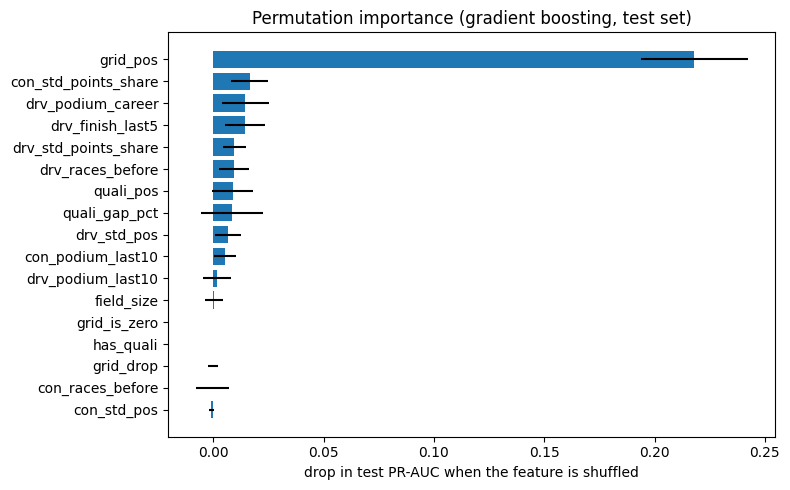

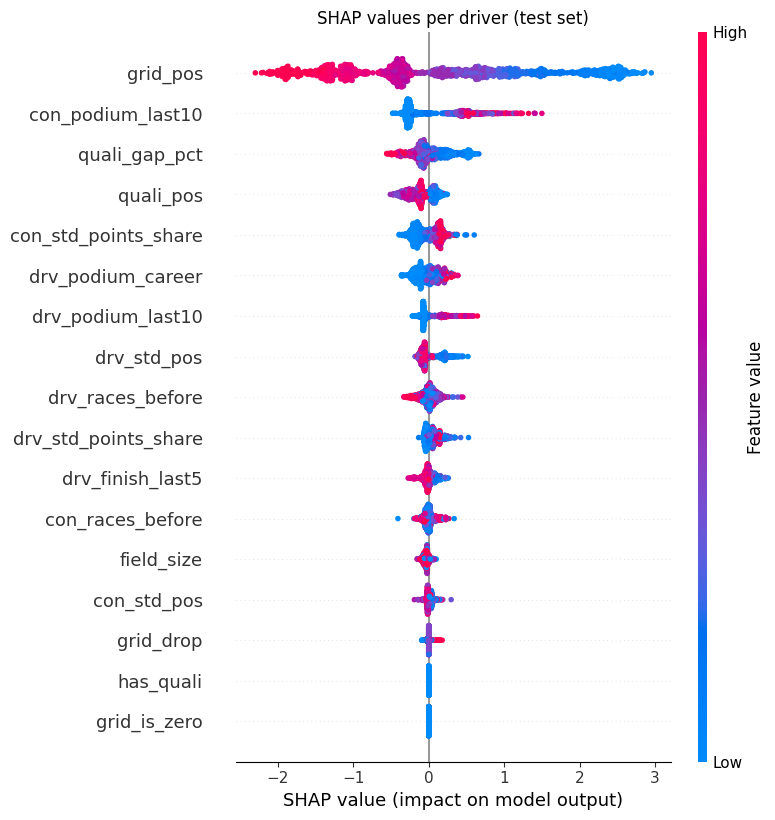

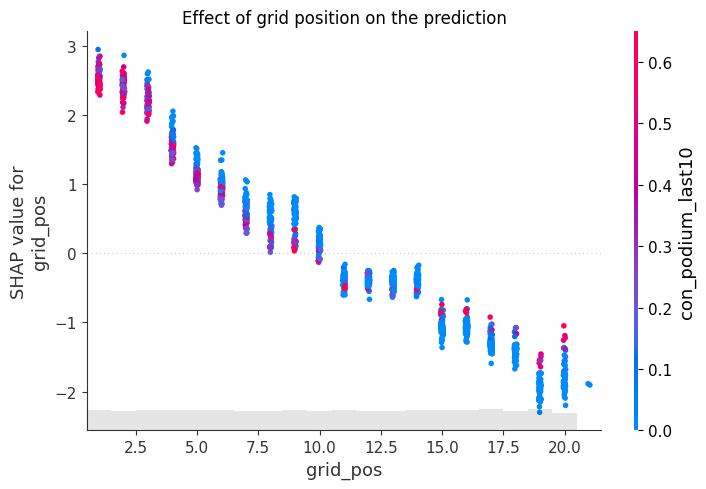

,PR_AUC_drop,mean_abs_SHAP,rank_perm,rank_SHAP
feature,,,,
grid_pos,0.2180,1.1340,1,1
con_podium_last10,0.0052,0.3515,10,2
quali_gap_pct,0.0084,0.1762,8,3
quali_pos,0.0087,0.1532,7,4
con_std_points_share,0.0165,0.1407,2,5
drv_podium_career,0.0146,0.1195,3,6
drv_podium_last10,0.0016,0.1110,11,7
drv_std_pos,0.0068,0.1094,9,8
drv_races_before,0.0094,0.0714,6,9


Spearman correlation of the two rankings: 0.68


In [42]:
import shap
from sklearn.inspection import permutation_importance

gb = final["gradient boosting"][0]

# --- Method 1: permutation importance (score = PR-AUC on the test set) ---
perm = permutation_importance(gb, X_te, y_te, scoring="average_precision",
                              n_repeats=20, random_state=42)
perm_df = (pd.DataFrame({"feature": FEATURES,
                         "PR_AUC_drop": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("PR_AUC_drop", ascending=False).reset_index(drop=True))

plt.figure(figsize=(8, 5))
plt.barh(perm_df["feature"][::-1], perm_df["PR_AUC_drop"][::-1], xerr=perm_df["std"][::-1])
plt.xlabel("drop in test PR-AUC when the feature is shuffled")
plt.title("Permutation importance (gradient boosting, test set)")
plt.tight_layout()
plt.show()

# --- Method 2: SHAP ---
explainer = shap.TreeExplainer(gb)
sv = explainer(X_te)

shap.plots.beeswarm(sv, max_display=17, show=False)
plt.title("SHAP values per driver (test set)")
plt.tight_layout()
plt.show()

# How the model uses grid position, coloured by team form
shap.plots.scatter(sv[:, "grid_pos"], color=sv[:, "con_podium_last10"], show=False)
plt.title("Effect of grid position on the prediction")
plt.tight_layout()
plt.show()

# --- Do the two methods agree? ---
compare = perm_df.set_index("feature")[["PR_AUC_drop"]].join(
    pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES, name="mean_abs_SHAP"))
compare["rank_perm"] = compare["PR_AUC_drop"].rank(ascending=False).astype(int)
compare["rank_SHAP"] = compare["mean_abs_SHAP"].rank(ascending=False).astype(int)
display(compare.sort_values("rank_SHAP").round(4))
print(f"Spearman correlation of the two rankings: "
      f"{compare['PR_AUC_drop'].corr(compare['mean_abs_SHAP'], method='spearman'):.2f}")

### Global explanations (selected model: gradient boosting, test set)

Neither method changes the model; the test set is used because it is the larger held-out set (204 podiums).

**Permutation importance** shuffles one feature and measures the drop in PR-AUC. **SHAP** splits every prediction into per-feature contributions (log-odds); the mean absolute value gives a global ranking.

| Feature | Permutation (PR-AUC drop) | Rank | Mean abs SHAP | Rank |
|---|---|---|---|---|
| grid_pos | 0.218 | 1 | 1.134 | 1 |
| con_podium_last10 | 0.005 | 10 | 0.352 | 2 |
| quali_gap_pct | 0.008 | 8 | 0.176 | 3 |
| quali_pos | 0.009 | 7 | 0.153 | 4 |
| con_std_points_share | 0.017 | 2 | 0.141 | 5 |
| drv_podium_career | 0.015 | 3 | 0.120 | 6 |

(full table above; Spearman correlation between the two rankings: 0.68)

**Findings.**
- **Both methods rank grid position first by a wide margin** (shuffling it lowers PR-AUC from 0.701 to about 0.48), consistent with the single-feature AUCs and the ablation.
- **The rankings differ below grid because of redundancy.** Team form moves predictions strongly (SHAP 2nd) but shuffling it barely hurts (permutation 10th), because the team's championship points share carries the same information. Permutation importance measures what the model cannot do without; SHAP measures what it actually uses.
- `has_quali` and `grid_is_zero` have zero importance in both: gradient boosting handles missing values natively, and grid 0 is already encoded in `grid_pos`.
- **The learned directions are sensible:** starting near the front, strong recent team and driver results, a high championship position and a small gap to pole all raise the prediction. A positive `grid_drop` (starting behind one's qualifying position) also raises it slightly, consistent with Question 1 (28.9% podium rate for penalised front-row qualifiers).
- **Interaction:** at the back of the grid, the penalty is smaller for strong teams (about -1.2 vs -2.0 in log-odds), reflecting fast cars recovering from penalties or pit-lane starts.

**Caution.** Importance shows what the model relies on, not what causes podiums. Grid position is the clearest pre-race trace of car speed; it does not make a car fast.

In [43]:
p_gb = gb.predict_proba(X_te)[:, 1]

cases = test[["raceId", "driverId", "year", "name"]].reset_index(drop=True)
cases["row"] = np.arange(len(cases))            # position in X_te and in sv
cases["prob"] = p_gb
cases["podium"] = y_te.values
cases = (cases
         .merge(clean["drivers"][["driverId", "forename", "surname"]], on="driverId", how="left")
         .merge(m[["raceId", "driverId", "positionOrder"]], on=["raceId", "driverId"], how="left"))

podiums = cases[cases["podium"] == 1].sort_values("prob")
others = cases[cases["podium"] == 0].sort_values("prob")
picks = {"confident correct podium": podiums.iloc[-1],
         "missed podium (false negative)": podiums.iloc[0],
         "false alarm (false positive)": others.iloc[-1]}

summary = pd.DataFrame(picks).T[["year", "name", "forename", "surname",
                                 "prob", "podium", "positionOrder"]]
display(summary)
display(X_te.iloc[[int(c["row"]) for c in picks.values()]][FEATURES]
        .set_axis(list(picks), axis=0).T.round(3))

,year,name,forename,surname,prob,podium,positionOrder
confident correct podium,2023,Dutch Grand Prix,Max,Verstappen,0.858811,1,1
missed podium (false negative),2024,São Paulo Grand Prix,Pierre,Gasly,0.005026,1,3
false alarm (false positive),2022,British Grand Prix,Max,Verstappen,0.836805,0,7


,confident correct podium,missed podium (false negative),false alarm (false positive)
grid_pos,1.000,13.000,2.000
grid_is_zero,0.000,0.000,0.000
field_size,19.000,19.000,20.000
drv_podium_last10,1.000,0.000,0.800
drv_finish_last5,1.000,13.200,1.400
drv_podium_career,0.509,0.027,0.447
drv_races_before,175.000,150.000,150.000
con_podium_last10,0.750,0.000,0.650
con_races_before,360.000,86.000,335.000
drv_std_pos,1.000,16.000,1.000


SHAP starting point (average model output): -3.29 log-odds = 3.6% probability

=== confident correct podium: Max Verstappen, 2023 Dutch Grand Prix | predicted 85.9% | finished P1


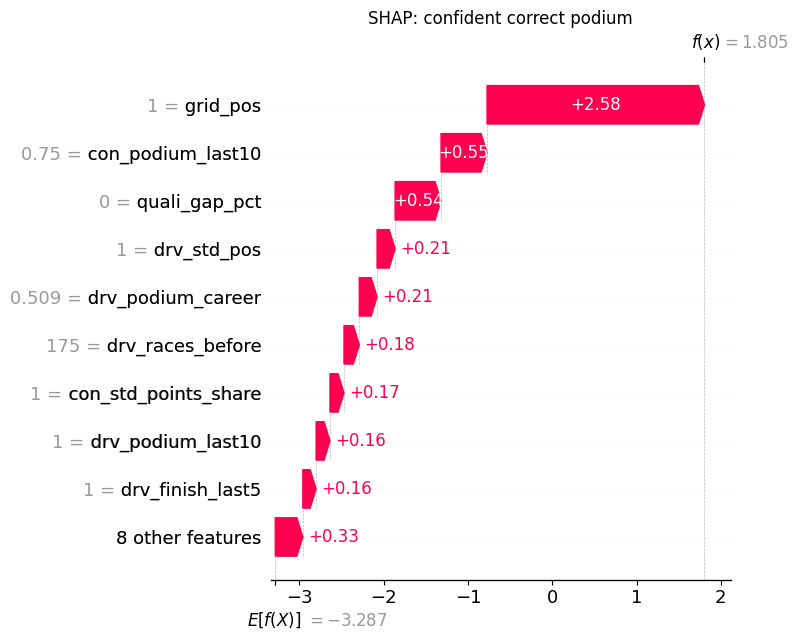

LIME input: model gives 85.9% (original row: 85.9%) | local fit R² = 0.52


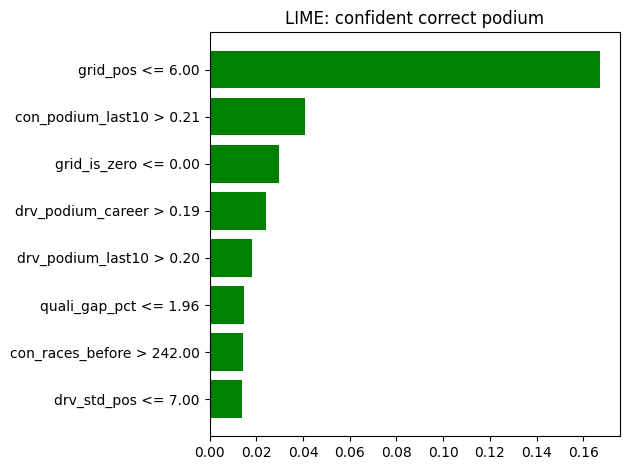

=== missed podium (false negative): Pierre Gasly, 2024 São Paulo Grand Prix | predicted 0.5% | finished P3


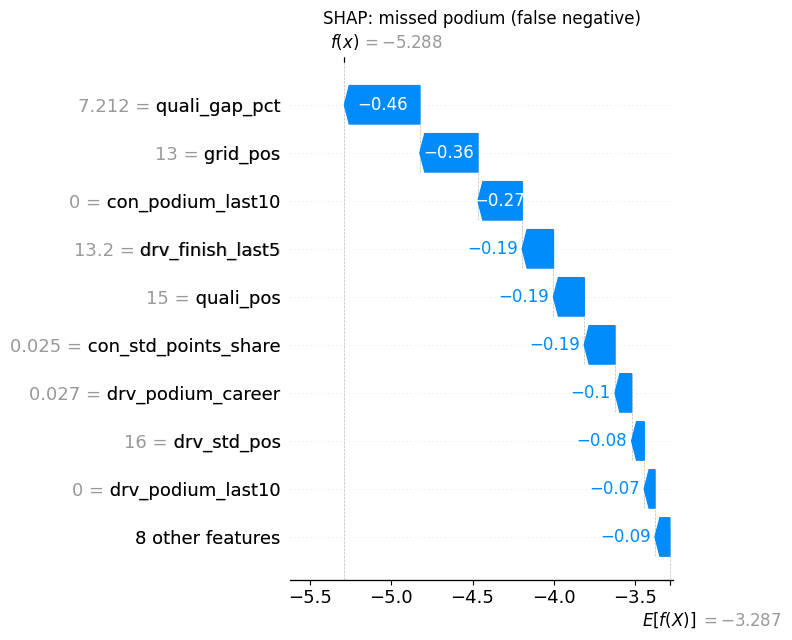

LIME input: model gives 0.5% (original row: 0.5%) | local fit R² = 0.11


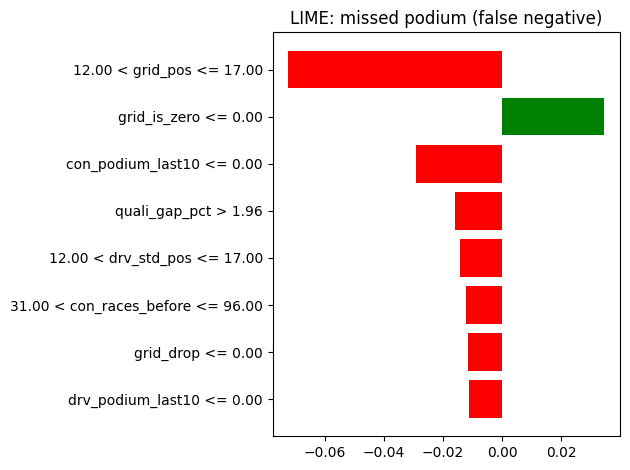

=== false alarm (false positive): Max Verstappen, 2022 British Grand Prix | predicted 83.7% | finished P7


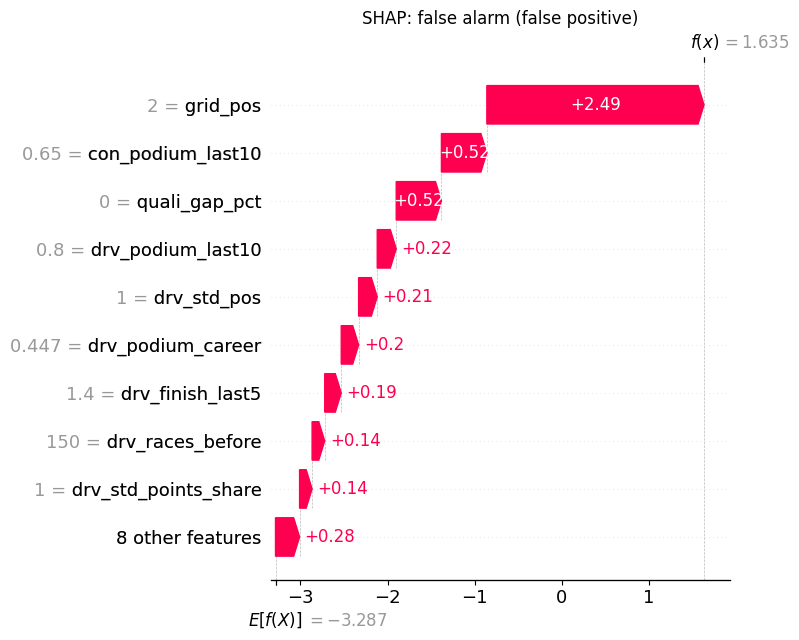

LIME input: model gives 83.7% (original row: 83.7%) | local fit R² = 0.53


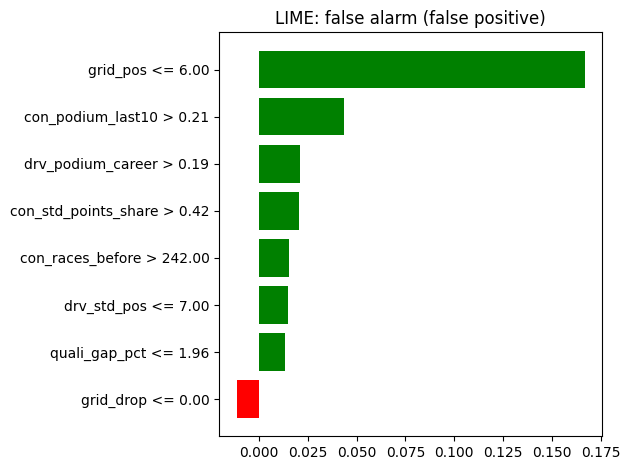

In [44]:
from lime.lime_tabular import LimeTabularExplainer

base_prob = 1 / (1 + np.exp(-sv.base_values[0]))
print(f"SHAP starting point (average model output): {sv.base_values[0]:.2f} log-odds "
      f"= {100 * base_prob:.1f}% probability\n")

medians = X_tr.median()
lime_explainer = LimeTabularExplainer(
    training_data=X_tr.fillna(medians).values,
    feature_names=FEATURES,
    class_names=["no podium", "podium"],
    mode="classification",
    random_state=42)

def predict_fn(arr):
    return gb.predict_proba(pd.DataFrame(arr, columns=FEATURES))

for label, c in picks.items():
    r = int(c["row"])
    who = f"{c['forename']} {c['surname']}, {c['year']} {c['name']}"
    print(f"=== {label}: {who} | predicted {100 * c['prob']:.1f}% | finished P{int(c['positionOrder'])}")

    # Local SHAP
    shap.plots.waterfall(sv[r], max_display=10, show=False)
    plt.title(f"SHAP: {label}")
    plt.tight_layout()
    plt.show()

    # LIME
    row_filled = X_te.iloc[r].fillna(medians).values
    exp = lime_explainer.explain_instance(row_filled, predict_fn, num_features=8, num_samples=5000)
    print(f"LIME input: model gives {100 * predict_fn(row_filled.reshape(1, -1))[0, 1]:.1f}% "
          f"(original row: {100 * c['prob']:.1f}%) | "
          f"local fit R² = {exp.score:.2f}")
    exp.as_pyplot_figure()
    plt.title(f"LIME: {label}")
    plt.tight_layout()
    plt.show()

### Local explanations (SHAP waterfall and LIME)

Three test-set cases for the selected model. SHAP starts from the model's average output (-3.29 log-odds, 3.6%) and adds each feature's contribution. LIME fits a simple local model around the driver; its R² shows how well it imitates the real model there.

| Case | Driver, race | Predicted | Finished | Main SHAP contributions | LIME R² |
|---|---|---|---|---|---|
| Confident correct podium | Verstappen, 2023 Dutch GP | 85.9% | P1 | grid (pole) +2.58, team form +0.55, gap to pole 0% +0.54 | 0.52 |
| Missed podium (false negative) | Gasly, 2024 São Paulo GP | 0.5% | P3 | gap to pole 7.2% -0.46, grid 13 -0.36, team form 0 -0.27 | 0.11 |
| False alarm (false positive) | Verstappen, 2022 British GP | 83.7% | P7 | grid 2 +2.49, team form +0.52, gap to pole 0% +0.52 | 0.53 |

**Findings.**
- **The reasoning is sensible in every case:** grid position dominates, followed by team form and qualifying pace. SHAP and LIME agree on the order of the main features (their units differ: log-odds vs probability).
- **Both errors come from race-day events, not from the pre-race picture.** The 2024 São Paulo GP was a wet race with a red flag, in which both Alpines reached the podium; nothing in the pre-race data describes weather or incidents. At the 2022 British GP, Verstappen's pre-race profile was almost identical to his 2023 Dutch GP win, but in-race damage dropped him to 7th. An 84% prediction is expected to fail roughly one time in six.
- **LIME is unreliable when the model's output is flat.** For the missed podium (prediction near 0%), LIME's local fit is weak (R² 0.11) and one of its conditions is hard to interpret, so we rely on the exact SHAP explanation for that case.

**Limitation.** Weather, safety cars, collisions and mechanical failures happen after our cutoff. They set a ceiling on how accurate any pre-race model can be.

# 12. Inference function

In [45]:
GB_THRESHOLD = float(best.loc[best["model"] == "gradient boosting", "best_threshold"].iloc[0])

REQUIRED = ["grid", "field_size"]
OPTIONAL = ["quali_pos", "quali_gap_pct",
            "drv_podium_last10", "drv_finish_last5", "drv_podium_career", "drv_races_before",
            "con_podium_last10", "con_races_before",
            "drv_std_pos", "drv_std_points_share", "con_std_pos", "con_std_points_share"]
POST_RACE_NAMES = {"positionOrder", "position", "positionText", "points", "statusId", "status",
                   "laps", "time", "milliseconds", "fastestLap", "fastestLapTime", "rank", "podium"}

def predict_podium(record, model=gb, threshold=GB_THRESHOLD, quali_cap=cap, n_reasons=3):
    """Podium probability for one driver, using only information available before the race."""
    # 1) Input checks
    leaked = POST_RACE_NAMES & set(record)
    if leaked:
        raise ValueError(f"Post-race information is not allowed (leakage): {sorted(leaked)}")
    unknown = set(record) - set(REQUIRED + OPTIONAL)
    if unknown:
        raise ValueError(f"Unknown inputs: {sorted(unknown)}")
    absent = [k for k in REQUIRED if record.get(k) is None]
    if absent:
        raise ValueError(f"Required inputs missing: {absent} (known for every driver after qualifying)")

    r = {k: np.nan if record.get(k) is None else float(record[k]) for k in REQUIRED + OPTIONAL}
    missing = [k for k in OPTIONAL if np.isnan(r[k])]

    # 2) Build the features exactly as in training
    grid_pos = r["field_size"] + 1 if r["grid"] == 0 else r["grid"]
    x = {"grid_pos": grid_pos,
         "grid_is_zero": float(r["grid"] == 0),
         "field_size": r["field_size"],
         "quali_pos": r["quali_pos"],
         "quali_gap_pct": np.minimum(r["quali_gap_pct"], quali_cap),
         "grid_drop": grid_pos - r["quali_pos"],
         "has_quali": float(not np.isnan(r["quali_pos"]))}
    for k in OPTIONAL:
        x.setdefault(k, r[k])
    X = pd.DataFrame([x])[FEATURES]

    # 3) Predict and explain
    prob = float(model.predict_proba(X)[0, 1])
    contrib = pd.Series(explainer(X).values[0], index=FEATURES)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:n_reasons]

    return {"podium_probability": round(prob, 3),
            "predicted_podium": prob >= threshold,
            "threshold": threshold,
            "missing_inputs": missing,
            "top_reasons": {f"{f} = {X.iloc[0][f]:.3g}": round(v, 2) for f, v in top.items()}}

In [46]:
def record_from_test(row):
    """Rebuild the raw inputs for one test row, as a caller would supply them."""
    t = X_te.iloc[row]
    rec = {"grid": 0 if t["grid_is_zero"] == 1 else t["grid_pos"], "field_size": t["field_size"]}
    rec.update({k: (None if pd.isna(t[k]) else t[k]) for k in OPTIONAL})
    return rec

# Demo 1: a complete record (Verstappen, 2023 Dutch Grand Prix)
row = int(picks["confident correct podium"]["row"])
full = record_from_test(row)
out_full = predict_podium(full)
print("Complete record:", full, "\n->", out_full, "\n")
assert abs(out_full["podium_probability"] - round(p_gb[row], 3)) < 1e-9   # same as the evaluation

# Demo 2: the same driver with qualifying and standings unknown
partial = {k: v for k, v in full.items()
           if k not in ["quali_pos", "quali_gap_pct", "drv_std_pos", "drv_std_points_share",
                        "con_std_pos", "con_std_points_share"]}
print("Partially missing record:", partial, "\n->", predict_podium(partial), "\n")

# Demo 3: a debutant with only grid and team information
rookie = {"grid": 9, "field_size": 20, "drv_races_before": 0,
          "con_podium_last10": 0.1, "con_races_before": 150}
print("Debutant record:", rookie, "\n->", predict_podium(rookie), "\n")

# Demo 4: the function refuses post-race information
try:
    predict_podium({**full, "points": 25})
except ValueError as e:
    print("Refused:", e)

Complete record: {'grid': np.float64(1.0), 'field_size': np.float64(19.0), 'quali_pos': np.float64(1.0), 'quali_gap_pct': np.float64(0.0), 'drv_podium_last10': np.float64(1.0), 'drv_finish_last5': np.float64(1.0), 'drv_podium_career': np.float64(0.5085714285714286), 'drv_races_before': np.float64(175.0), 'con_podium_last10': np.float64(0.75), 'con_races_before': np.float64(360.0), 'drv_std_pos': np.float64(1.0), 'drv_std_points_share': np.float64(1.0), 'con_std_pos': np.float64(1.0), 'con_std_points_share': np.float64(1.0)} 
-> {'podium_probability': 0.859, 'predicted_podium': True, 'threshold': 0.34, 'missing_inputs': [], 'top_reasons': {'grid_pos = 1': 2.58, 'con_podium_last10 = 0.75': 0.55, 'quali_gap_pct = 0': 0.54}} 

Partially missing record: {'grid': np.float64(1.0), 'field_size': np.float64(19.0), 'drv_podium_last10': np.float64(1.0), 'drv_finish_last5': np.float64(1.0), 'drv_podium_career': np.float64(0.5085714285714286), 'drv_races_before': np.float64(175.0), 'con_podium_last

### Inference function

`predict_podium(record)` takes one driver's raw pre-race inputs and returns the podium probability, the yes/no prediction at the validation threshold (0.34), the list of missing inputs, and the three features that moved the prediction most (local SHAP, log-odds).

**Design.**
- The caller supplies raw values (e.g. `grid = 0`); the function builds the 17 features with the training recipe (grid 0 placed behind the last car, `quali_gap_pct` capped at the training value 11.54, `grid_drop` and `has_quali` derived).
- `grid` and `field_size` are required: they were never missing in training, so the model never learned to handle their absence, and both are always known after qualifying.
- All other inputs are optional; gradient boosting learned to handle their absence (3-66% missing in training).
- Post-race inputs (points, finishing position, status, ...) and unknown names are rejected with an error.

**Demonstrations.**

| Record | Probability | Prediction | Missing inputs |
|---|---|---|---|
| Complete (Verstappen, 2023 Dutch GP) | 85.9% (identical to the evaluation) | podium | none |
| Same driver, qualifying and standings removed | 74.2% | podium | 6 |
| Debutant: grid 9, team information only (`drv_races_before = 0`) | 7.6% | no podium | 9 |
| Complete record + `points` | refused | | |

**Limitation: missing values are not neutral.** In training, missing qualifying data mainly meant a pre-1994 race, and missing constructor standings meant round 1 of a season or a race before 1958. The model therefore reads these gaps as signs of an older race, in which grid position was less decisive (pole: 53% podium rate before 1994 vs 81% from 2014). Removing qualifying from a modern pole-sitter lowers his prediction (85.9% to 74.2%), while for the mid-field debutant the missing inputs each add about +0.10 log-odds. For modern races, qualifying and standings are always available before the race and should be supplied.